# Satellite Collision Risk Evaluator — Full Pipeline
**Autonomous SG 2026 · Airbus Track · Challenge #1**

**Goal:** for every conjunction data message (CDM, one row), estimate the collision probability `risk = log10(Pc)` and assign an operational tier:

| Tier | Rule (NASA/ESA thresholds from the brief) |
|---|---|
| **Critical** (manoeuvre) | Pc ≥ 1e-4 (risk ≥ −4) **or** miss distance < 1 km |
| **Elevated** | 1e-6 ≤ Pc < 1e-4 **or** miss distance 1–5 km |
| **Safe** | Pc < 1e-6 **and** miss distance > 5 km |

**Design:** ML estimates Pc (the column `risk` is *not* an allowed input), the tier is then assigned by the deterministic rule above. Miss distance is an input, so the miss-distance part of the rule is exact; the ML adds value on the Pc part.

**Pipeline:** load (13 allowed columns) → EDA → inspect test set (distribution match, drift) → feature engineering (incl. causal per-event history) → Pearson feature selection → scaling + PCA (99% variance) → models:
Elliptic Envelope (anomaly detection) · Ridge · Random Forest · XGBoost · LightGBM · LightGBM classifier · MLP · GRU (RNN) · causal 1D-CNN → evaluation on challenge tiers → 24 h warnings & insights → failure cases → export.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import pearsonr, ks_2samp
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.model_selection import GroupShuffleSplit
from sklearn.covariance import EllipticEnvelope
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (f1_score, recall_score, precision_score, confusion_matrix,
                             mean_squared_error, roc_auc_score, classification_report)
import lightgbm as lgb, xgboost as xgb
import torch, torch.nn as nn

warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
torch.set_num_threads(max(1, os.cpu_count() or 1))

# Put train_data.csv / test_data.csv next to this notebook (or change DATA_DIR)
DATA_DIR = '.' if os.path.exists('train_data.csv') else '/mnt/user-data/uploads'
OUT_DIR = 'outputs'; os.makedirs(OUT_DIR, exist_ok=True)

TIERS = ['SAFE', 'ELEVATED', 'CRITICAL']
TIER_COLORS = {'SAFE': '#2a9d8f', 'ELEVATED': '#e9a23b', 'CRITICAL': '#d1495b'}
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

## 1. Load data (only the columns the brief allows)
`risk` is loaded **only as the label**, never as an input.

In [2]:
ALLOWED = ['event_id', 'time_to_tca', 'miss_distance', 'relative_speed',
           'relative_position_r', 'relative_position_t', 'relative_position_n',
           'c_object_type', 'c_sigma_r', 't_sigma_r', 'max_risk_estimate', 'F10', 'AP']
LABEL = 'risk'

train_raw = pd.read_csv(f'{DATA_DIR}/train_data.csv', usecols=ALLOWED + [LABEL])
test_raw  = pd.read_csv(f'{DATA_DIR}/test_data.csv',  usecols=ALLOWED + [LABEL])
print('train', train_raw.shape, 'events', train_raw.event_id.nunique())
print('test ', test_raw.shape,  'events', test_raw.event_id.nunique())
train_raw.head()

train (162634, 14) events 13154
test  (24484, 14) events 2167


,event_id,time_to_tca,risk,max_risk_estimate,miss_distance,relative_speed,relative_position_r,relative_position_t,relative_position_n,c_object_type,t_sigma_r,c_sigma_r,F10,AP
0,0,1.566798,-10.204955,-7.834756,14923.0,13792.0,453.8,5976.6,-13666.8,UNKNOWN,4.057932,266.722309,89.0,11.0
1,0,1.207494,-10.355758,-7.848937,14544.0,13792.0,474.3,5821.2,-13319.8,UNKNOWN,3.526780,262.191819,89.0,11.0
2,0,0.952193,-10.345631,-7.847406,14475.0,13792.0,474.6,5796.2,-13256.1,UNKNOWN,3.362037,261.666544,89.0,11.0
3,0,0.579669,-10.337809,-7.845880,14579.0,13792.0,472.7,5838.9,-13350.7,UNKNOWN,3.075781,261.759718,89.0,14.0
4,0,0.257806,-10.391260,-7.852942,14510.0,13792.0,478.7,5811.1,-13288.0,UNKNOWN,3.392176,260.727425,89.0,14.0


In [3]:
def tier_from(risk, miss_m):
    """Challenge-1 tier rule. risk = log10(Pc), miss distance in metres."""
    risk, miss_m = np.asarray(risk), np.asarray(miss_m)
    return np.where((risk >= -4) | (miss_m < 1000), 'CRITICAL',
           np.where((risk >= -6) | (miss_m <= 5000), 'ELEVATED', 'SAFE'))

def pc_tier(risk):
    """Tier from Pc alone (ignores miss distance) — isolates what the ML has to learn."""
    risk = np.asarray(risk)
    return np.where(risk >= -4, 'CRITICAL', np.where(risk >= -6, 'ELEVATED', 'SAFE'))

for d in (train_raw, test_raw):
    d['tier'] = tier_from(d[LABEL], d.miss_distance)
    d['pc_tier'] = pc_tier(d[LABEL])
    d['crit_reason'] = np.select([(d[LABEL] >= -4) & (d.miss_distance < 1000), d[LABEL] >= -4, d.miss_distance < 1000],
                                 ['Pc and miss', 'Pc only', 'miss only'], 'not critical')

summary = pd.DataFrame({
    'train rows': train_raw.tier.value_counts(), 'train %': train_raw.tier.value_counts(normalize=True).mul(100).round(2),
    'test rows': test_raw.tier.value_counts(),  'test %': test_raw.tier.value_counts(normalize=True).mul(100).round(2)}).loc[TIERS]
display(summary)
print('Why rows are CRITICAL (train):'); print(train_raw.crit_reason.value_counts())

,train rows,train %,test rows,test %
tier,,,,
SAFE,115812,71.21,15756,64.35
ELEVATED,35192,21.64,6501,26.55
CRITICAL,11630,7.15,2227,9.10


Why rows are CRITICAL (train):
crit_reason
not critical    151004
miss only        10914
Pc and miss        391
Pc only            325
Name: count, dtype: int64


## 2. Exploratory data analysis

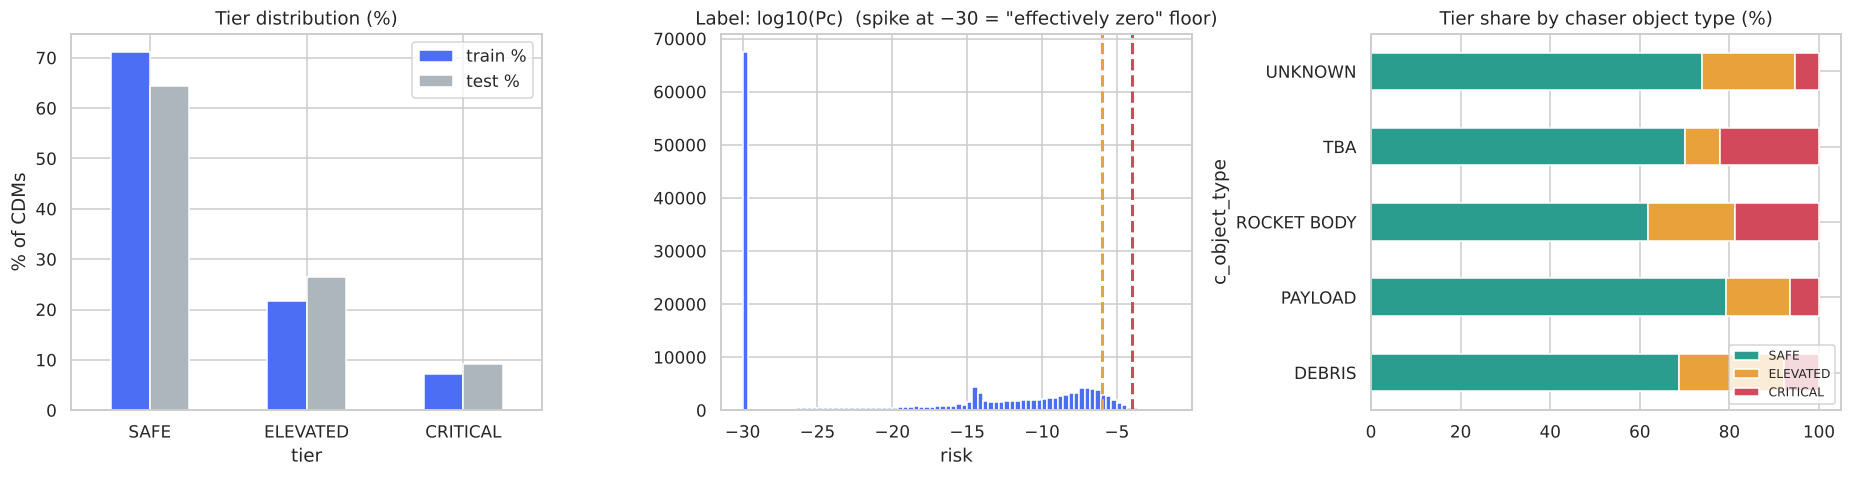

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
(summary[['train %', 'test %']]).plot.bar(ax=ax[0], color=['#4c6ef5', '#adb5bd'], rot=0)
ax[0].set_title('Tier distribution (%)'); ax[0].set_ylabel('% of CDMs')

ax[1].hist(train_raw[LABEL], bins=80, color='#4c6ef5')
for t, c in [(-6, TIER_COLORS['ELEVATED']), (-4, TIER_COLORS['CRITICAL'])]:
    ax[1].axvline(t, color=c, ls='--', lw=2)
ax[1].set_title('Label: log10(Pc)  (spike at −30 = "effectively zero" floor)'); ax[1].set_xlabel('risk')

pd.crosstab(train_raw.c_object_type, train_raw.tier, normalize='index')[TIERS].mul(100).plot.barh(
    stacked=True, ax=ax[2], color=[TIER_COLORS[t] for t in TIERS])
ax[2].set_title('Tier share by chaser object type (%)'); ax[2].legend(loc='lower right', fontsize=8)
plt.tight_layout(); plt.show()

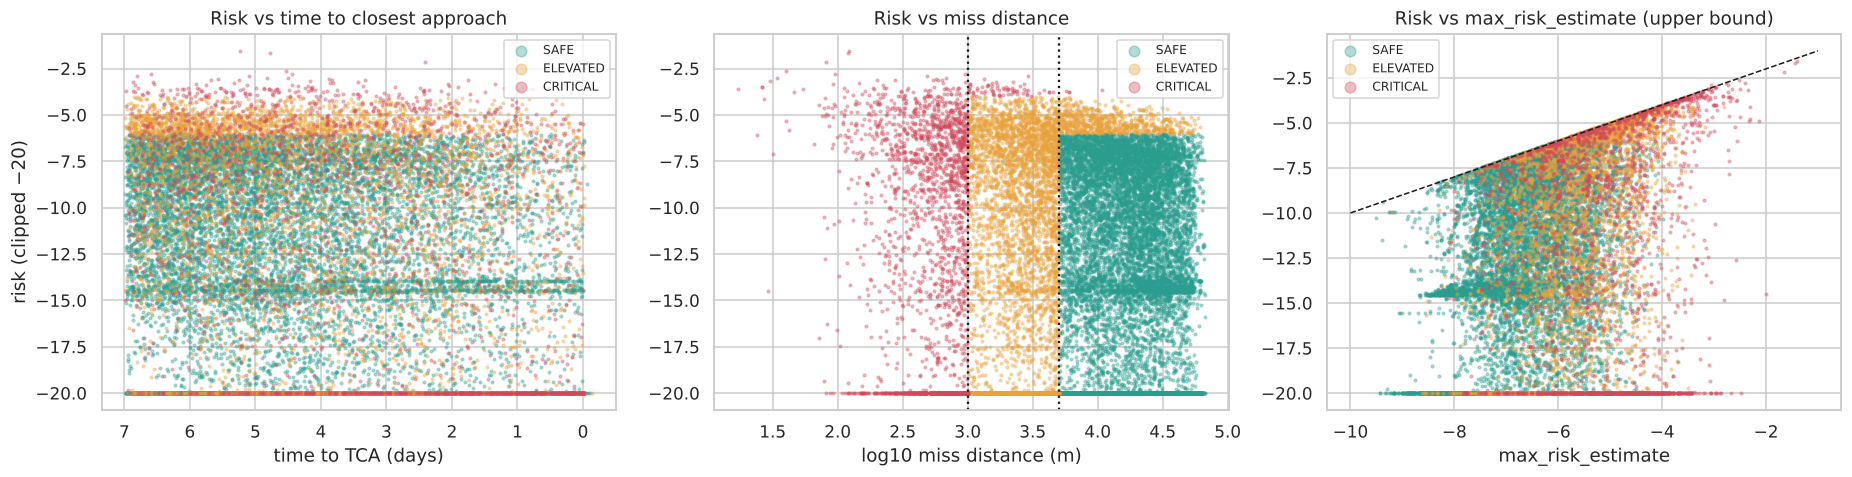

In [5]:
samp = train_raw.sample(30000, random_state=SEED)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for t in TIERS:
    s = samp[samp.tier == t]
    ax[0].scatter(s.time_to_tca, s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
    ax[1].scatter(np.log10(s.miss_distance), s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
    ax[2].scatter(s.max_risk_estimate, s[LABEL].clip(-20), s=3, alpha=.35, c=TIER_COLORS[t], label=t)
ax[0].set(xlabel='time to TCA (days)', ylabel='risk (clipped −20)', title='Risk vs time to closest approach'); ax[0].invert_xaxis()
ax[1].set(xlabel='log10 miss distance (m)', title='Risk vs miss distance')
ax[1].axvline(3, color='k', ls=':'); ax[1].axvline(np.log10(5000), color='k', ls=':')
ax[2].set(xlabel='max_risk_estimate', title='Risk vs max_risk_estimate (upper bound)')
ax[2].plot([-10, -1], [-10, -1], 'k--', lw=1)
for a in ax: a.legend(markerscale=4, fontsize=8)
plt.tight_layout(); plt.show()

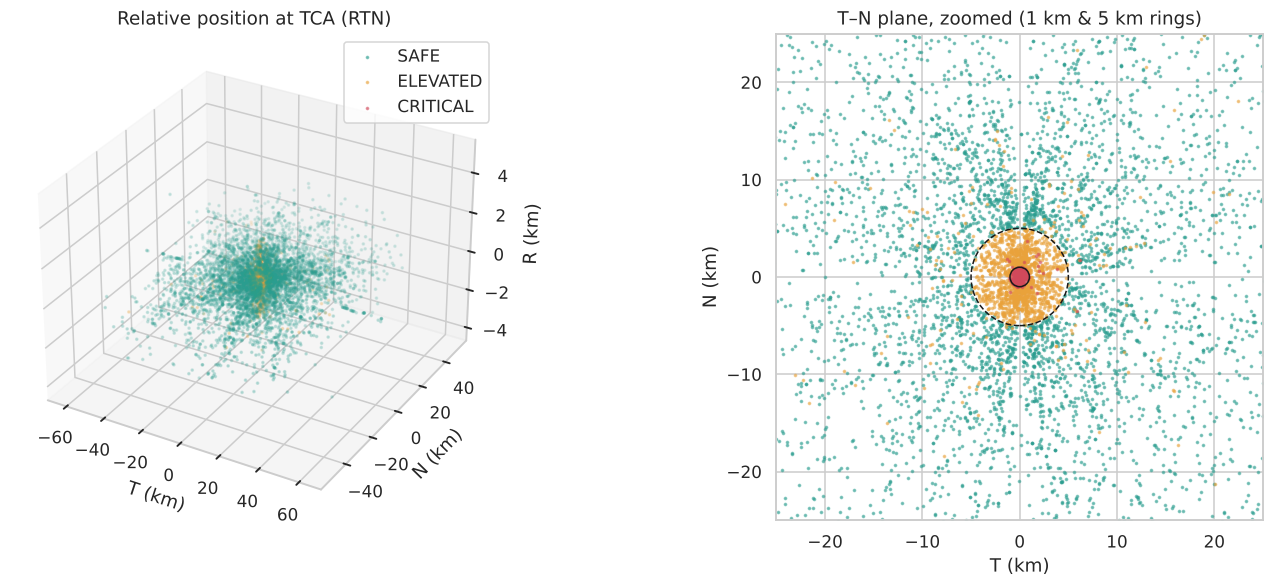

In [6]:
# Encounter geometry in the RTN frame (relative position of chaser w.r.t. target at TCA)
from mpl_toolkits.mplot3d import Axes3D  # noqa
s = train_raw.sample(8000, random_state=1)
fig = plt.figure(figsize=(14, 5.5))
a3 = fig.add_subplot(121, projection='3d')
for t in TIERS:
    q = s[s.tier == t]
    a3.scatter(q.relative_position_t / 1e3, q.relative_position_n / 1e3, q.relative_position_r / 1e3, s=2, c=TIER_COLORS[t], label=t, alpha=.5)
a3.set_xlabel('T (km)'); a3.set_ylabel('N (km)'); a3.set_zlabel('R (km)'); a3.set_title('Relative position at TCA (RTN)'); a3.legend()
a2 = fig.add_subplot(122)
for t in TIERS:
    q = s[s.tier == t]
    a2.scatter(q.relative_position_t / 1e3, q.relative_position_n / 1e3, s=2, c=TIER_COLORS[t], alpha=.5, label=t)
a2.add_patch(plt.Circle((0, 0), 5, fill=False, ls='--', color='k')); a2.add_patch(plt.Circle((0, 0), 1, fill=False, color='k'))
a2.set(xlim=(-25, 25), ylim=(-25, 25), xlabel='T (km)', ylabel='N (km)', title='T–N plane, zoomed (1 km & 5 km rings)'); a2.set_aspect('equal')
plt.tight_layout(); plt.show()

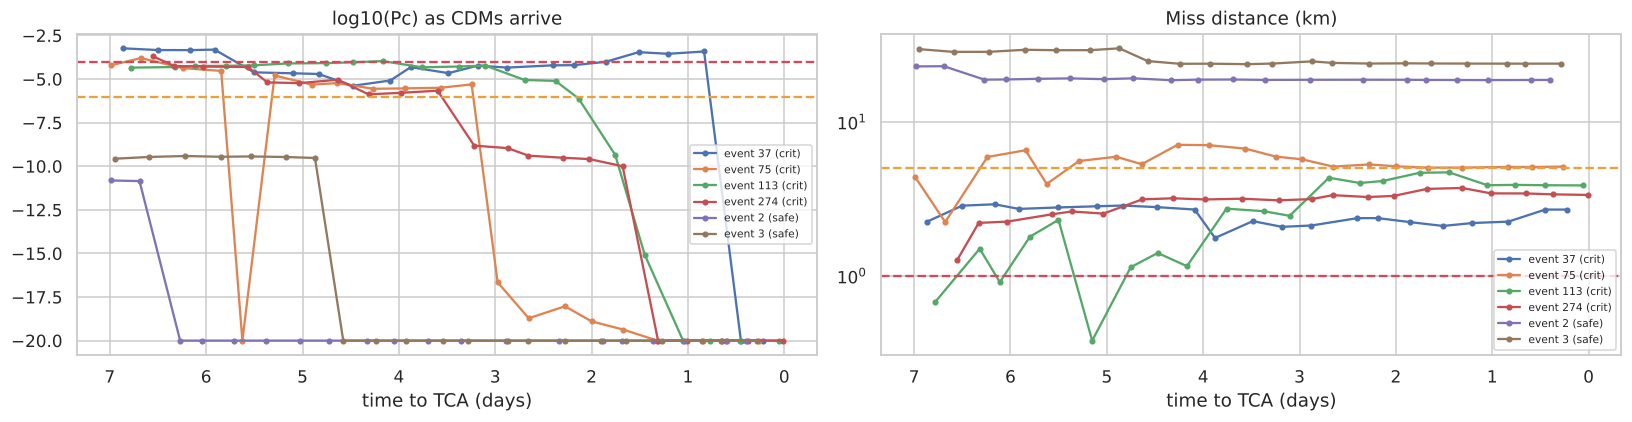

In [7]:
# Risk evolution of a few events that end up Critical vs Safe
ev_crit = train_raw.groupby('event_id').filter(lambda g: (g[LABEL] >= -4).any() and len(g) > 8).event_id.unique()[:4]
ev_safe = train_raw.groupby('event_id').filter(lambda g: (g.tier == 'SAFE').all() and len(g) > 8).event_id.unique()[:2]
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for e in list(ev_crit) + list(ev_safe):
    g = train_raw[train_raw.event_id == e].sort_values('time_to_tca', ascending=False)
    lbl = f'event {e} ({"crit" if e in ev_crit else "safe"})'
    ax[0].plot(g.time_to_tca, g[LABEL].clip(-20), marker='o', ms=3, label=lbl)
    ax[1].plot(g.time_to_tca, g.miss_distance / 1e3, marker='o', ms=3, label=lbl)
ax[0].axhline(-4, color=TIER_COLORS['CRITICAL'], ls='--'); ax[0].axhline(-6, color=TIER_COLORS['ELEVATED'], ls='--')
ax[1].axhline(1, color=TIER_COLORS['CRITICAL'], ls='--'); ax[1].axhline(5, color=TIER_COLORS['ELEVATED'], ls='--')
ax[0].set(title='log10(Pc) as CDMs arrive', xlabel='time to TCA (days)'); ax[1].set(title='Miss distance (km)', xlabel='time to TCA (days)', yscale='log')
for a in ax: a.invert_xaxis(); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

## 3. Look at the test data before choosing features
The test set defines the operating conditions the model must generalise to, so the training data and features should match it.
We only look at test **inputs** here (ranges, missingness, drift). Using test **labels** to pick features would leak the answer.

,train min,train max,test min,test max,train NaN %,test NaN %
AP,0.000000,1.080000e+02,0.000000,1.060000e+02,4.19,5.43
F10,66.000000,2.460000e+02,66.000000,1.820000e+02,4.19,5.43
c_sigma_r,0.927165,6.378136e+07,1.160012,6.378136e+07,0.01,0.02
max_risk_estimate,-9.814175,-1.082442e+00,-10.045951,-1.263444e+00,0.00,0.00
miss_distance,9.000000,6.737300e+04,17.000000,6.592700e+04,0.00,0.00
relative_position_n,-50995.500000,5.099680e+04,-50774.500000,5.052700e+04,0.00,0.00
relative_position_r,-4815.000000,5.284100e+03,-2586.800000,2.406900e+03,0.00,0.00
relative_position_t,-62184.200000,6.218430e+04,-61304.100000,6.128750e+04,0.00,0.00
relative_speed,4.000000,1.713800e+04,58.000000,1.695600e+04,0.00,0.00
t_sigma_r,0.699496,6.378136e+07,0.738897,6.378136e+07,0.00,0.00


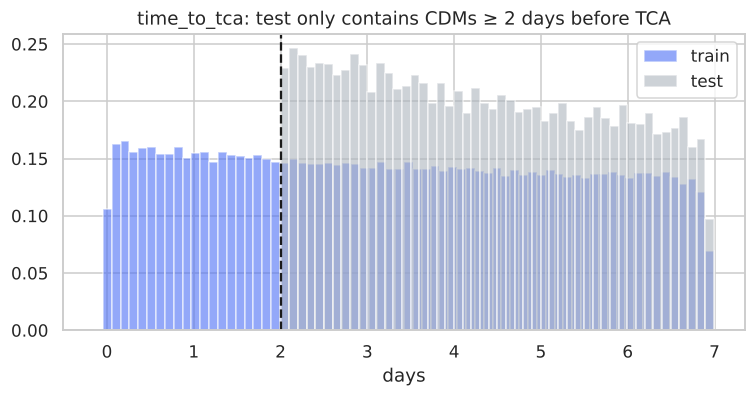

In [8]:
cmp = pd.DataFrame({'train min': train_raw[ALLOWED[1:7] + ALLOWED[8:]].min(), 'train max': train_raw[ALLOWED[1:7] + ALLOWED[8:]].max(),
                    'test min': test_raw[ALLOWED[1:7] + ALLOWED[8:]].min(), 'test max': test_raw[ALLOWED[1:7] + ALLOWED[8:]].max(),
                    'train NaN %': train_raw[ALLOWED].isna().mean().mul(100).round(2), 'test NaN %': test_raw[ALLOWED].isna().mean().mul(100).round(2)}).dropna(subset=['train min'])
display(cmp)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(train_raw.time_to_tca, bins=70, alpha=.6, density=True, label='train', color='#4c6ef5')
ax.hist(test_raw.time_to_tca, bins=50, alpha=.6, density=True, label='test', color='#adb5bd')
ax.axvline(2, color='k', ls='--'); ax.set(title='time_to_tca: test only contains CDMs ≥ 2 days before TCA', xlabel='days'); ax.legend(); plt.show()

**Key finding:** every test CDM is ≥ 2 days before closest approach, while train goes down to ~0 days (where uncertainty collapses and risk is much easier).
Training on the late CDMs would teach the model a regime it never sees at test time, so **train is filtered to `time_to_tca ≥ 2`**.
This is also the operationally meaningful framing: a warning ≥ 2 days ahead leaves time to plan a manoeuvre.

The full train set is kept (`train_full`) for the 24-hour warning analysis in section 10.

In [9]:
train_full = train_raw.copy()
train_raw = train_raw[train_raw.time_to_tca >= 2].copy()
print(f'train after filter: {len(train_raw):,} rows, {train_raw.event_id.nunique():,} events')
display(pd.DataFrame({'train(≥2d) %': train_raw.tier.value_counts(normalize=True).mul(100).round(2),
                      'test %': test_raw.tier.value_counts(normalize=True).mul(100).round(2)}).loc[TIERS])

train after filter: 111,939 rows, 11,942 events


,train(≥2d) %,test %
tier,,
SAFE,70.40,64.35
ELEVATED,22.28,26.55
CRITICAL,7.31,9.10


## 4. Feature engineering
Row-level physics features plus **causal** per-event history (only CDMs that arrived *earlier* in the same event — no peeking at later messages).
Rows are ordered from far to near TCA (time_to_tca descending).

In [10]:
OBJ_TYPES = ['DEBRIS', 'PAYLOAD', 'ROCKET BODY', 'UNKNOWN', 'TBA']

def engineer(df):
    d = df.sort_values(['event_id', 'time_to_tca'], ascending=[True, False]).reset_index(drop=True)
    sig_c = d.c_sigma_r.fillna(d.c_sigma_r.median())
    sig_comb = np.sqrt(d.t_sigma_r**2 + sig_c**2)
    f = pd.DataFrame(index=d.index)
    f['time_to_tca'] = d.time_to_tca
    f['log_miss'] = np.log10(d.miss_distance.clip(lower=1))
    f['log_speed'] = np.log10(d.relative_speed.clip(lower=1))
    f['rel_r'], f['rel_t'], f['rel_n'] = d.relative_position_r, d.relative_position_t, d.relative_position_n
    f['log_abs_r'] = np.log10(d.relative_position_r.abs() + 1)
    f['log_abs_t'] = np.log10(d.relative_position_t.abs() + 1)
    f['log_abs_n'] = np.log10(d.relative_position_n.abs() + 1)
    f['log_t_sigma_r'] = np.log10(d.t_sigma_r)
    f['log_c_sigma_r'] = np.log10(sig_c)
    f['log_sigma_comb'] = np.log10(sig_comb)
    f['log_miss_over_sigma'] = f.log_miss - f.log_sigma_comb          # how many sigmas apart (radial proxy)
    f['log_r_over_sigma'] = f.log_abs_r - f.log_sigma_comb
    f['max_risk_estimate'] = d.max_risk_estimate
    f['F10'], f['AP'] = d.F10, d.AP
    for o in OBJ_TYPES:
        f[f'obj_{o.replace(" ", "_")}'] = (d.c_object_type == o).astype(int)
    # ---- causal history within each event ----
    g = d.groupby('event_id')
    f['cdm_index'] = g.cumcount()
    f['mre_prev'] = g.max_risk_estimate.shift(1).fillna(d.max_risk_estimate)
    f['mre_delta'] = d.max_risk_estimate - f.mre_prev
    f['mre_cummax'] = g.max_risk_estimate.cummax()
    f['mre_first'] = g.max_risk_estimate.transform('first')
    f['mre_trend'] = d.max_risk_estimate - f.mre_first
    f['log_miss_prev'] = f.groupby(d.event_id).log_miss.shift(1).fillna(f.log_miss)
    f['log_miss_delta'] = f.log_miss - f.log_miss_prev
    f['log_miss_cummin'] = f.groupby(d.event_id).log_miss.cummin()
    f['log_c_sigma_delta'] = f.log_c_sigma_r - f.groupby(d.event_id).log_c_sigma_r.shift(1).fillna(f.log_c_sigma_r)
    meta = d[['event_id', 'time_to_tca', 'miss_distance', 'c_object_type', 'relative_position_r', 'relative_position_t',
              'relative_position_n', 'max_risk_estimate', LABEL, 'tier', 'pc_tier']].copy()
    meta['y'] = d[LABEL].clip(lower=-20)          # −30 floor → −20 (does not change any tier)
    return f, meta

X_all, M_all = engineer(train_raw)
X_test_all, M_test = engineer(test_raw)
print('engineered features:', X_all.shape[1]); X_all.describe().T.head(12)

engineered features: 32


,count,mean,std,min,25%,50%,75%,max
time_to_tca,111939.0,4.424304,1.425904,2.000014,3.185255,4.399526,5.658008,6.993832
log_miss,111939.0,3.978946,0.550514,0.954243,3.672744,4.093842,4.403103,4.828486
log_speed,111939.0,3.951184,0.331828,0.602060,3.867821,4.088349,4.161008,4.232666
rel_r,111939.0,-39.957608,637.685527,-4815.000000,-298.100000,-26.100000,235.700000,5284.100000
rel_t,111939.0,8.813408,14826.735318,-61287.600000,-5854.350000,0.200000,5808.300000,61304.000000
rel_n,111939.0,160.754146,16067.884603,-50995.500000,-6870.900000,49.500000,7450.850000,50994.200000
log_abs_r,111939.0,2.365254,0.553685,0.000000,2.057666,2.426023,2.721605,3.723053
log_abs_t,111939.0,3.614333,0.739725,0.000000,3.207284,3.765959,4.174234,4.787496
log_abs_n,111939.0,3.737587,0.642578,0.041393,3.384694,3.854215,4.222943,4.707540
log_t_sigma_r,111939.0,0.859494,0.903156,-0.155215,0.594031,0.762441,0.914455,7.804694


## 5. Feature selection
Three filters, in order:
1. **Relevance** — Pearson r with the target `log10(Pc)` on train: keep |r| ≥ 0.05 and p < 0.001.
2. **Test-set check** — two-sample KS statistic between train and test feature distributions: drop features whose distribution shifts strongly (KS > 0.25), since what is learnt from them won't transfer.
3. **Redundancy** — for feature pairs with |r| > 0.95, keep the one more correlated with the target.

In [11]:
y_all = M_all.y.values
rows = []
for c in X_all.columns:
    x = X_all[c].values; m = ~np.isnan(x)
    if np.nanstd(x) == 0: rows.append((c, 0, 1, np.nan)); continue
    r, p = pearsonr(x[m], y_all[m])
    ks = ks_2samp(X_all[c].dropna(), X_test_all[c].dropna()).statistic
    rows.append((c, r, p, ks))
fs = pd.DataFrame(rows, columns=['feature', 'pearson_r', 'p_value', 'ks_train_vs_test']).set_index('feature')
fs['abs_r'] = fs.pearson_r.abs()
fs['relevant'] = (fs.abs_r >= 0.05) & (fs.p_value < 1e-3)
fs['stable_on_test'] = fs.ks_train_vs_test <= 0.25
fs = fs.sort_values('abs_r', ascending=False)

cand = fs[fs.relevant & fs.stable_on_test].index.tolist()
corr = X_all[cand].corr().abs()
dropped_redundant = set()
for i, a in enumerate(cand):
    for b in cand[i + 1:]:
        if a in dropped_redundant or b in dropped_redundant: continue
        if corr.loc[a, b] > 0.95:
            dropped_redundant.add(b if fs.abs_r[a] >= fs.abs_r[b] else a)
SELECTED = [c for c in cand if c not in dropped_redundant]
fs['selected'] = fs.index.isin(SELECTED)
print(f'{len(SELECTED)} selected features:', SELECTED)
print('dropped (redundant):', sorted(dropped_redundant))
print('dropped (drift on test):', fs[fs.relevant & ~fs.stable_on_test].index.tolist())
display(fs.round(4))

21 selected features: ['time_to_tca', 'cdm_index', 'log_miss_over_sigma', 'log_r_over_sigma', 'max_risk_estimate', 'log_c_sigma_r', 'log_miss', 'log_miss_prev', 'log_abs_n', 'log_miss_cummin', 'mre_trend', 'obj_PAYLOAD', 'log_sigma_comb', 'log_abs_r', 'mre_cummax', 'mre_first', 'obj_UNKNOWN', 'log_abs_t', 'mre_delta', 'log_c_sigma_delta', 'obj_ROCKET_BODY']
dropped (redundant): ['mre_prev']
dropped (drift on test): []


,pearson_r,p_value,ks_train_vs_test,abs_r,relevant,stable_on_test,selected
feature,,,,,,,
time_to_tca,0.3521,0.0000,0.0302,0.3521,True,True,True
cdm_index,-0.3382,0.0000,0.0517,0.3382,True,True,True
log_miss_over_sigma,-0.2713,0.0000,0.0158,0.2713,True,True,True
log_r_over_sigma,-0.2661,0.0000,0.0230,0.2661,True,True,True
max_risk_estimate,0.2604,0.0000,0.0665,0.2604,True,True,True
log_c_sigma_r,0.2404,0.0000,0.0574,0.2404,True,True,True
mre_prev,0.2291,0.0000,0.0680,0.2291,True,True,False
log_miss,-0.2210,0.0000,0.0649,0.2210,True,True,True
log_miss_prev,-0.2152,0.0000,0.0632,0.2152,True,True,True


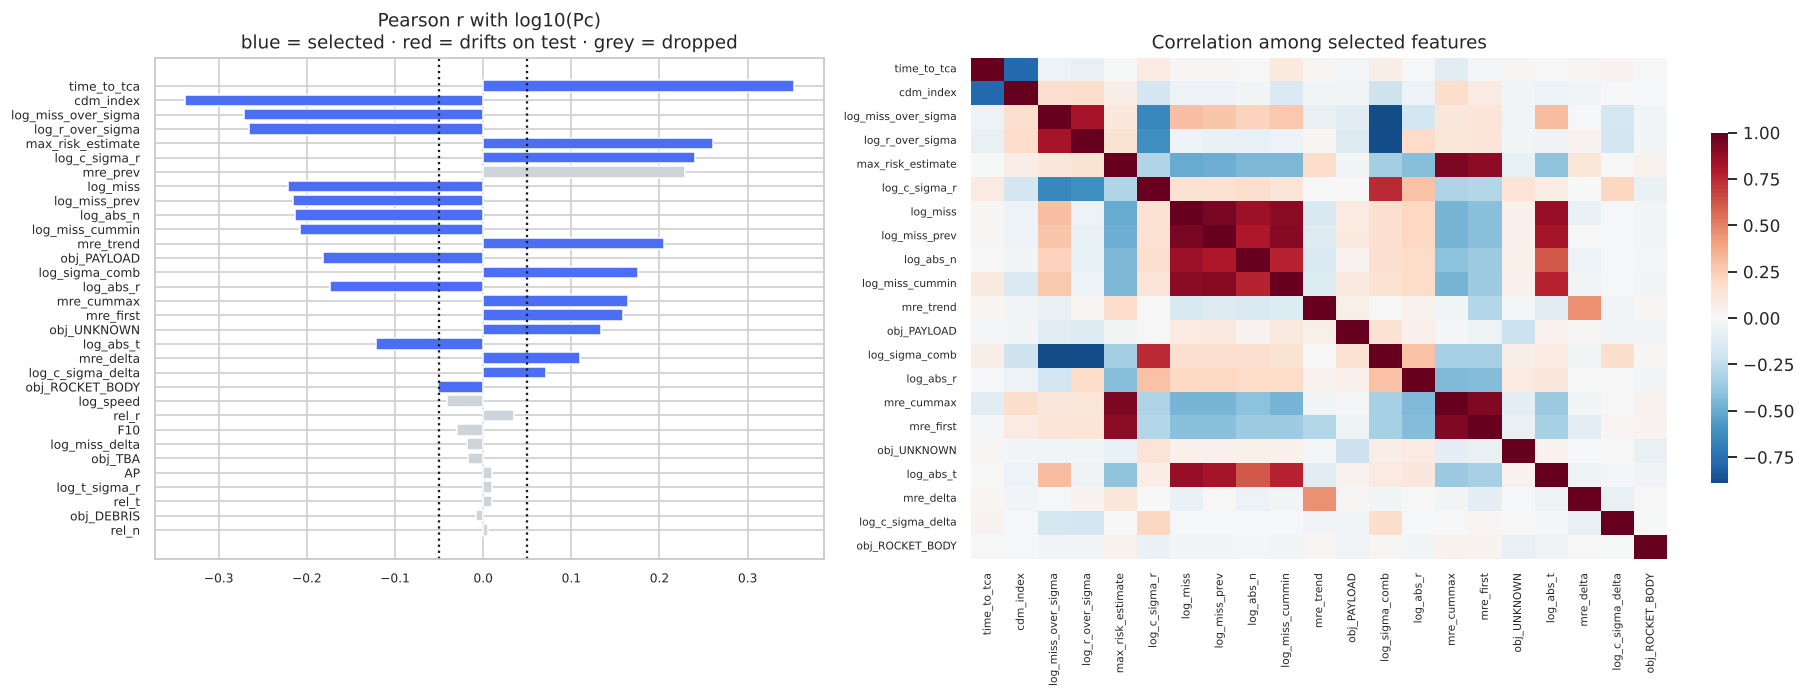

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1, 1.3]})
cols = np.where(fs.selected, '#4c6ef5', np.where(~fs.stable_on_test, '#d1495b', '#ced4da'))
ax[0].barh(fs.index[::-1], fs.pearson_r[::-1], color=cols[::-1])
ax[0].axvline(0.05, ls=':', c='k'); ax[0].axvline(-0.05, ls=':', c='k')
ax[0].set_title('Pearson r with log10(Pc)\nblue = selected · red = drifts on test · grey = dropped'); ax[0].tick_params(labelsize=8)
sns.heatmap(X_all[SELECTED].corr(), cmap='RdBu_r', center=0, ax=ax[1], cbar_kws={'shrink': .7}, xticklabels=True, yticklabels=True)
ax[1].set_title('Correlation among selected features'); ax[1].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

## 6. Train/validation split, scaling and PCA (99 % variance)
Split **by event** (GroupShuffleSplit) so CDMs from one event never land in both train and validation.
Imputer, scaler and PCA are fit on the training split only.

PCA: 21 features → 15 components retain 0.9929 of variance


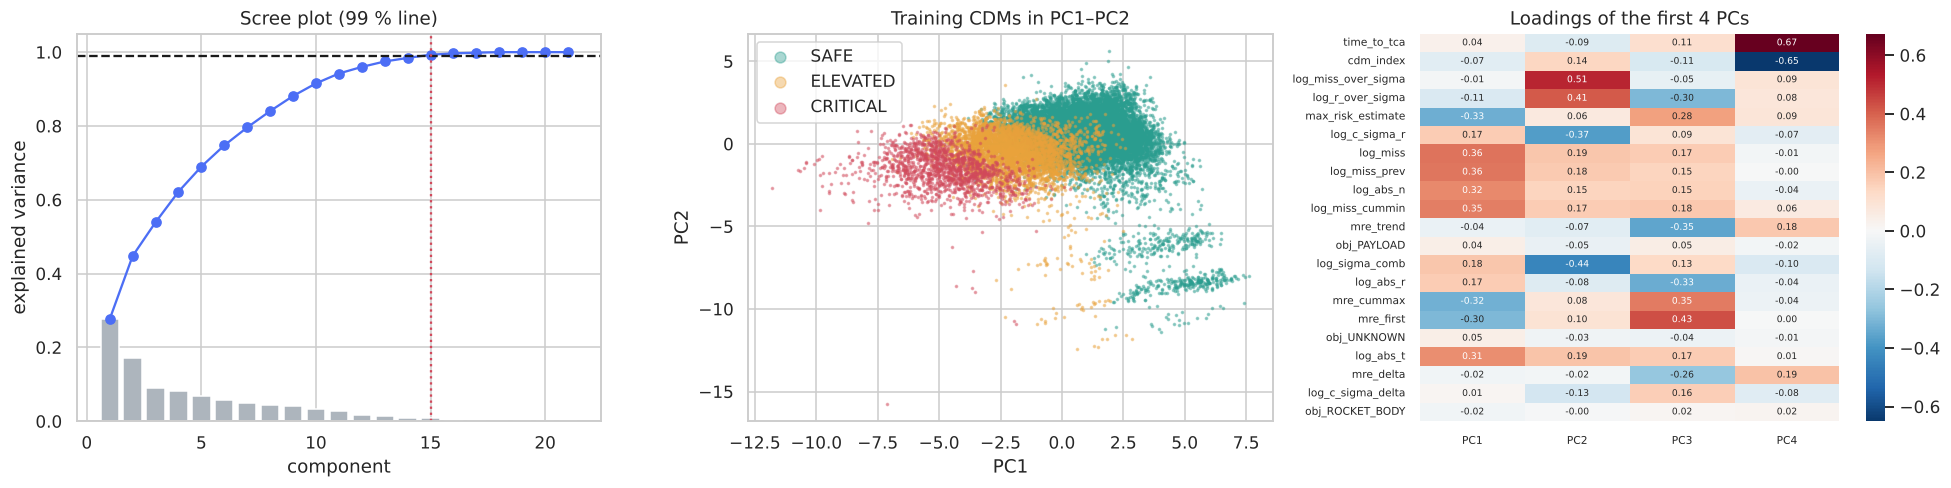

In [13]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, va_idx = next(gss.split(X_all, y_all, groups=M_all.event_id))
X_tr_raw, X_va_raw, X_te_raw = X_all.iloc[tr_idx][SELECTED], X_all.iloc[va_idx][SELECTED], X_test_all[SELECTED]
M_tr, M_va = M_all.iloc[tr_idx].reset_index(drop=True), M_all.iloc[va_idx].reset_index(drop=True)
y_tr, y_va, y_te = M_tr.y.values, M_va.y.values, M_test.y.values

imputer = SimpleImputer(strategy='median').fit(X_tr_raw)
scaler = StandardScaler().fit(imputer.transform(X_tr_raw))
prep = lambda X: scaler.transform(imputer.transform(X))
Z_tr, Z_va, Z_te = prep(X_tr_raw), prep(X_va_raw), prep(X_te_raw)

pca = PCA(n_components=0.99, svd_solver='full', random_state=SEED).fit(Z_tr)
P_tr, P_va, P_te = pca.transform(Z_tr), pca.transform(Z_va), pca.transform(Z_te)
print(f'PCA: {len(SELECTED)} features → {pca.n_components_} components retain {pca.explained_variance_ratio_.sum():.4f} of variance')

full_pca = PCA().fit(Z_tr)
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
cum = np.cumsum(full_pca.explained_variance_ratio_)
ax[0].bar(range(1, len(cum) + 1), full_pca.explained_variance_ratio_, color='#adb5bd')
ax[0].plot(range(1, len(cum) + 1), cum, 'o-', c='#4c6ef5'); ax[0].axhline(.99, c='k', ls='--')
ax[0].axvline(pca.n_components_, c=TIER_COLORS['CRITICAL'], ls=':')
ax[0].set(title='Scree plot (99 % line)', xlabel='component', ylabel='explained variance')
sidx = np.random.RandomState(0).choice(len(P_tr), 20000, replace=False)
tiers_tr = M_tr.tier.values
for t in TIERS:
    m = sidx[tiers_tr[sidx] == t]
    ax[1].scatter(P_tr[m, 0], P_tr[m, 1], s=2, alpha=.4, c=TIER_COLORS[t], label=t)
ax[1].set(title='Training CDMs in PC1–PC2', xlabel='PC1', ylabel='PC2'); ax[1].legend(markerscale=5)
load = pd.DataFrame(pca.components_[:4].T, index=SELECTED, columns=[f'PC{i+1}' for i in range(4)])
sns.heatmap(load, cmap='RdBu_r', center=0, ax=ax[2], annot=True, fmt='.2f', annot_kws={'size': 6}); ax[2].tick_params(labelsize=7)
ax[2].set_title('Loadings of the first 4 PCs')
plt.tight_layout(); plt.show()

## 7. Evaluation framework (challenge metrics)
Every model outputs a predicted `log10(Pc)`; the tier is then `tier_from(pred_risk, miss_distance)`.

Reported metrics:
- **Critical recall** (most important: a missed manoeuvre is the costly error) and Critical precision (false-alarm load)
- **Macro-F1** over the 3 tiers
- **Pc-tier macro-F1** — tiers from Pc only, which isolates the part the model actually has to learn (miss-distance rules are exact)
- **High-risk recall** — share of true Pc ≥ 1e-6 CDMs caught
- **RMSE** of log10(Pc) on all rows and on the high-risk rows (true risk ≥ −6)

**Baseline** (what an operator gets with no ML): use `max_risk_estimate` (the conservative upper-bound Pc provided in the CDM) directly as the Pc.

In [14]:
RESULTS = {}

def evaluate(name, pred_risk, meta, split='val', store=True, verbose=False):
    pred_risk = np.asarray(pred_risk, dtype=float)
    y_true_t, y_pred_t = meta.tier.values, tier_from(pred_risk, meta.miss_distance.values)
    pc_true, pc_pred = meta.pc_tier.values, pc_tier(pred_risk)
    hr = meta.y.values >= -6
    res = {
        'critical_recall': recall_score(y_true_t, y_pred_t, labels=['CRITICAL'], average='macro', zero_division=0),
        'critical_precision': precision_score(y_true_t, y_pred_t, labels=['CRITICAL'], average='macro', zero_division=0),
        'macro_f1': f1_score(y_true_t, y_pred_t, labels=TIERS, average='macro'),
        'pc_macro_f1': f1_score(pc_true, pc_pred, labels=TIERS, average='macro'),
        'pc_critical_recall': recall_score(pc_true, pc_pred, labels=['CRITICAL'], average='macro', zero_division=0),
        'highrisk_recall': (pred_risk[hr] >= -6).mean() if hr.any() else np.nan,
        'rmse': mean_squared_error(meta.y.values, np.clip(pred_risk, -20, 0)) ** .5,
        'rmse_highrisk': mean_squared_error(meta.y.values[hr], np.clip(pred_risk[hr], -20, 0)) ** .5 if hr.any() else np.nan,
    }
    if store: RESULTS[(name, split)] = res
    if verbose: print(name, split, {k: round(v, 4) for k, v in res.items()})
    return res

def plot_cms(preds, meta, title_suffix=''):
    n = len(preds); fig, ax = plt.subplots(1, n, figsize=(4.6 * n, 4))
    ax = np.atleast_1d(ax)
    for a, (nm, pr) in zip(ax, preds.items()):
        cm = confusion_matrix(meta.tier.values, tier_from(pr, meta.miss_distance.values), labels=TIERS)
        cmn = cm / cm.sum(1, keepdims=True)
        sns.heatmap(cmn, annot=np.array([[f'{cmn[i,j]:.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]), fmt='',
                    cmap='Blues', xticklabels=TIERS, yticklabels=TIERS, cbar=False, ax=a, annot_kws={'size': 8})
        a.set(title=f'{nm}{title_suffix}', xlabel='predicted', ylabel='true')
    plt.tight_layout(); plt.show()

# Sample weights: high-risk CDMs are rare but matter most
def weights(y): return 1 + 4 * (y >= -6) + 10 * (y >= -4)
w_tr = weights(y_tr)

VAL_PRED, TEST_PRED = {}, {}
VAL_PRED['Baseline (max_risk_estimate)'] = M_va.max_risk_estimate.values
TEST_PRED['Baseline (max_risk_estimate)'] = M_test.max_risk_estimate.values
evaluate('Baseline (max_risk_estimate)', VAL_PRED['Baseline (max_risk_estimate)'], M_va, verbose=True);

Baseline (max_risk_estimate) val {'critical_recall': 1.0, 'critical_precision': 0.9261, 'macro_f1': 0.8368, 'pc_macro_f1': 0.5524, 'pc_critical_recall': 1.0, 'highrisk_recall': np.float64(1.0), 'rmse': 9.0373, 'rmse_highrisk': 0.5341}


## 8. Models
### 8.1 Elliptic Envelope — unsupervised anomaly detection
Fit a robust Gaussian envelope on the PCA features of **Pc-safe** CDMs only. CDMs far outside the envelope are anomalous → potentially high risk.
The Mahalanobis score is mapped to a pseudo-log10(Pc) by isotonic calibration on the training split, so it can go through the same tier rule.

In [15]:
from sklearn.isotonic import IsotonicRegression
t0 = time.time()
safe_mask = y_tr < -6
fit_idx = np.random.RandomState(SEED).choice(np.where(safe_mask)[0], min(30000, safe_mask.sum()), replace=False)
ee = EllipticEnvelope(contamination=0.02, support_fraction=0.9, random_state=SEED).fit(P_tr[fit_idx])
score = lambda P: -ee.decision_function(P)          # higher = more anomalous
s_tr, s_va, s_te = score(P_tr), score(P_va), score(P_te)
print('Elliptic envelope ROC-AUC (val) for detecting Pc ≥ 1e-6:', round(roc_auc_score(y_va >= -6, s_va), 4))
iso = IsotonicRegression(out_of_bounds='clip').fit(s_tr, y_tr)
VAL_PRED['Elliptic Envelope'], TEST_PRED['Elliptic Envelope'] = iso.predict(s_va), iso.predict(s_te)
evaluate('Elliptic Envelope', VAL_PRED['Elliptic Envelope'], M_va, verbose=True); print(f'{time.time()-t0:.1f}s')

Elliptic envelope ROC-AUC (val) for detecting Pc ≥ 1e-6: 0.5886
Elliptic Envelope val {'critical_recall': 0.962, 'critical_precision': 1.0, 'macro_f1': 0.9564, 'pc_macro_f1': 0.3184, 'pc_critical_recall': 0.0, 'highrisk_recall': np.float64(0.0), 'rmse': 5.624, 'rmse_highrisk': 8.3763}
5.1s


### 8.2 Classical ML regressors on PCA features
Ridge (linear), Random Forest, XGBoost, LightGBM — all predict log10(Pc) with risk-weighted samples.
A LightGBM on the raw selected features (no PCA) is included as an ablation: trees often do better without rotation.

In [16]:
classical = {
    'Ridge': Ridge(alpha=1.0),
    'Random Forest': RandomForestRegressor(n_estimators=150, max_depth=18, min_samples_leaf=5, max_features=0.6, n_jobs=-1, random_state=SEED),
    'XGBoost': xgb.XGBRegressor(n_estimators=600, learning_rate=0.05, max_depth=7, subsample=0.8, colsample_bytree=0.8,
                                tree_method='hist', n_jobs=-1, random_state=SEED, early_stopping_rounds=50),
    'LightGBM': lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                                  colsample_bytree=0.8, random_state=SEED, verbose=-1),
}
for nm, mdl in classical.items():
    t0 = time.time()
    if nm == 'XGBoost':
        mdl.fit(P_tr, y_tr, sample_weight=w_tr, eval_set=[(P_va, y_va)], verbose=False)
    elif nm == 'LightGBM':
        mdl.fit(P_tr, y_tr, sample_weight=w_tr, eval_set=[(P_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
    else:
        mdl.fit(P_tr, y_tr, sample_weight=w_tr)
    VAL_PRED[nm], TEST_PRED[nm] = mdl.predict(P_va), mdl.predict(P_te)
    evaluate(nm, VAL_PRED[nm], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

# Ablation: LightGBM on raw selected features (no PCA)
t0 = time.time()
lgb_raw = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.03, num_leaves=63, subsample=0.8, subsample_freq=1,
                            colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_raw.fit(Z_tr, y_tr, sample_weight=w_tr, eval_set=[(Z_va, y_va)], callbacks=[lgb.early_stopping(100, verbose=False)])
VAL_PRED['LightGBM (no PCA)'], TEST_PRED['LightGBM (no PCA)'] = lgb_raw.predict(Z_va), lgb_raw.predict(Z_te)
evaluate('LightGBM (no PCA)', VAL_PRED['LightGBM (no PCA)'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

Ridge val {'critical_recall': 0.9785, 'critical_precision': 0.8879, 'macro_f1': 0.9369, 'pc_macro_f1': 0.5015, 'pc_critical_recall': 0.5164, 'highrisk_recall': np.float64(0.2802), 'rmse': 4.4605, 'rmse_highrisk': 3.1851}
   0.2s


Random Forest val {'critical_recall': 0.9689, 'critical_precision': 0.9993, 'macro_f1': 0.9682, 'pc_macro_f1': 0.6743, 'pc_critical_recall': 0.3361, 'highrisk_recall': np.float64(0.4656), 'rmse': 3.2511, 'rmse_highrisk': 2.3888}
   37.3s


XGBoost val {'critical_recall': 0.9772, 'critical_precision': 0.9866, 'macro_f1': 0.9685, 'pc_macro_f1': 0.6961, 'pc_critical_recall': 0.459, 'highrisk_recall': np.float64(0.5381), 'rmse': 3.14, 'rmse_highrisk': 2.1686}
   5.0s


LightGBM val {'critical_recall': 0.9785, 'critical_precision': 0.9872, 'macro_f1': 0.9688, 'pc_macro_f1': 0.7129, 'pc_critical_recall': 0.4836, 'highrisk_recall': np.float64(0.5567), 'rmse': 3.1196, 'rmse_highrisk': 2.1079}
   12.8s


LightGBM (no PCA) val {'critical_recall': 0.9829, 'critical_precision': 0.9892, 'macro_f1': 0.972, 'pc_macro_f1': 0.7709, 'pc_critical_recall': 0.6393, 'highrisk_recall': np.float64(0.6207), 'rmse': 2.9162, 'rmse_highrisk': 1.7537}
   12.7s


### 8.3 Direct tier classifier (LightGBM, class-balanced)
Instead of regressing Pc, classify the **Pc-tier** directly, then combine with the exact miss-distance rule.
The predicted class probabilities are turned into an expected log10(Pc) only so the same evaluation applies.

In [17]:
t0 = time.time()
cls_map = {t: i for i, t in enumerate(TIERS)}
lgb_cls = lgb.LGBMClassifier(n_estimators=800, learning_rate=0.03, num_leaves=63, class_weight='balanced',
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1)
lgb_cls.fit(P_tr, M_tr.pc_tier.map(cls_map), eval_set=[(P_va, M_va.pc_tier.map(cls_map))],
            callbacks=[lgb.early_stopping(100, verbose=False)])
def cls_to_risk(proba):   # representative log10(Pc) per predicted class
    return np.array([-10.0, -5.0, -3.0])[proba.argmax(1)]
VAL_PRED['LightGBM classifier'] = cls_to_risk(lgb_cls.predict_proba(P_va))
TEST_PRED['LightGBM classifier'] = cls_to_risk(lgb_cls.predict_proba(P_te))
evaluate('LightGBM classifier', VAL_PRED['LightGBM classifier'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

LightGBM classifier val {'critical_recall': 0.981, 'critical_precision': 0.9898, 'macro_f1': 0.9699, 'pc_macro_f1': 0.7586, 'pc_critical_recall': 0.5492, 'highrisk_recall': np.float64(0.8066), 'rmse': 6.515, 'rmse_highrisk': 2.011}
   23.7s


### 8.4 Deep learning — MLP on PCA features (PyTorch)

In [18]:
def train_torch(model, make_batches, val_fn, epochs=25, lr=2e-3, patience=5, name='model'):
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=2)
    best, best_state, bad, hist = np.inf, None, 0, []
    for ep in range(epochs):
        model.train(); tl = []
        for loss_fn in make_batches():
            opt.zero_grad(); loss = loss_fn(model); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); tl.append(loss.item())
        vl = val_fn(model); sched.step(vl); hist.append((np.mean(tl), vl))
        if vl < best - 1e-4: best, best_state, bad = vl, {k: v.clone() for k, v in model.state_dict().items()}, 0
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(best_state)
    print(f'{name}: {len(hist)} epochs, best val weighted-MSE {best:.4f}')
    return hist

class MLP(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d, 128), nn.BatchNorm1d(128), nn.ReLU(), nn.Dropout(.2),
                                 nn.Linear(128, 64), nn.BatchNorm1d(64), nn.ReLU(), nn.Dropout(.1),
                                 nn.Linear(64, 32), nn.ReLU(), nn.Linear(32, 1))
    def forward(self, x): return self.net(x).squeeze(-1)

T = lambda a: torch.tensor(np.asarray(a), dtype=torch.float32)
Ptr_t, ytr_t, wtr_t, Pva_t, yva_t, wva_t = T(P_tr), T(y_tr), T(w_tr), T(P_va), T(y_va), T(weights(y_va))

def mlp_batches(bs=1024):
    perm = torch.randperm(len(Ptr_t))
    for i in range(0, len(perm), bs):
        b = perm[i:i + bs]
        yield lambda m, b=b: (wtr_t[b] * (m(Ptr_t[b]) - ytr_t[b]) ** 2).mean()

def mlp_val(m):
    m.eval()
    with torch.no_grad(): return (wva_t * (m(Pva_t) - yva_t) ** 2).mean().item()

t0 = time.time()
torch.manual_seed(SEED)
mlp = MLP(P_tr.shape[1])
hist_mlp = train_torch(mlp, mlp_batches, mlp_val, epochs=40, name='MLP')
mlp.eval()
with torch.no_grad():
    VAL_PRED['MLP'], TEST_PRED['MLP'] = mlp(Pva_t).numpy(), mlp(T(P_te)).numpy()
evaluate('MLP', VAL_PRED['MLP'], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

MLP: 38 epochs, best val weighted-MSE 9.9848


MLP val {'critical_recall': 0.9911, 'critical_precision': 0.9745, 'macro_f1': 0.9721, 'pc_macro_f1': 0.7758, 'pc_critical_recall': 0.7459, 'highrisk_recall': np.float64(0.7816), 'rmse': 3.0713, 'rmse_highrisk': 1.2017}
   18.7s


### 8.5 Sequence models — GRU (RNN) and causal 1D-CNN
Each event is a time series of CDMs. These models read the PCA features of **all CDMs received so far** in the event and predict log10(Pc) for the current one (many-to-many).
The GRU is unidirectional and the CNN uses left-only (causal) padding, so neither sees future messages.

In [19]:
def to_sequences(P, meta, y=None):
    ev = meta.event_id.values
    starts = np.r_[0, np.where(ev[1:] != ev[:-1])[0] + 1]; ends = np.r_[starts[1:], len(ev)]
    L = (ends - starts).max(); n = len(starts); d = P.shape[1]
    Xs, Ys, Ms, Ws = np.zeros((n, L, d), np.float32), np.zeros((n, L), np.float32), np.zeros((n, L), np.float32), np.zeros((n, L), np.float32)
    for k, (s, e) in enumerate(zip(starts, ends)):
        Xs[k, :e - s] = P[s:e]; Ms[k, :e - s] = 1
        if y is not None: Ys[k, :e - s] = y[s:e]; Ws[k, :e - s] = weights(y[s:e])
    return T(Xs), T(Ys), T(Ms), T(Ws), (starts, ends)

# meta frames are already sorted by event then time_to_tca desc (engineer()), splits preserve that order
S_tr = to_sequences(P_tr, M_tr, y_tr); S_va = to_sequences(P_va, M_va, y_va); S_te = to_sequences(P_te, M_test, y_te)
print('sequence tensors:', S_tr[0].shape, S_va[0].shape, S_te[0].shape)

class GRUNet(nn.Module):
    def __init__(self, d, h=64):
        super().__init__()
        self.inp = nn.Linear(d, h); self.gru = nn.GRU(h, h, num_layers=2, batch_first=True, dropout=.1)
        self.head = nn.Sequential(nn.Linear(h + d, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        o, _ = self.gru(torch.relu(self.inp(x)))
        return self.head(torch.cat([o, x], -1)).squeeze(-1)

class CausalCNN(nn.Module):
    def __init__(self, d, c=64, k=3):
        super().__init__()
        self.k = k
        self.convs = nn.ModuleList([nn.Conv1d(d, c, k, dilation=1), nn.Conv1d(c, c, k, dilation=2), nn.Conv1d(c, c, k, dilation=4)])
        self.head = nn.Sequential(nn.Linear(c + d, 64), nn.ReLU(), nn.Linear(64, 1))
    def forward(self, x):
        h = x.transpose(1, 2)
        for i, conv in enumerate(self.convs):
            pad = (self.k - 1) * conv.dilation[0]
            h = torch.relu(conv(nn.functional.pad(h, (pad, 0))))   # left-pad only → causal
        return self.head(torch.cat([h.transpose(1, 2), x], -1)).squeeze(-1)

def seq_batches(S, bs=128):
    X, Y, M, W, _ = S
    def gen():
        perm = torch.randperm(len(X))
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            yield lambda m, b=b: ((m(X[b]) - Y[b]) ** 2 * W[b] * M[b]).sum() / M[b].sum()
    return gen

def seq_val(S):
    X, Y, M, W, _ = S
    def f(m):
        m.eval()
        with torch.no_grad(): return (((m(X) - Y) ** 2 * W * M).sum() / M.sum()).item()
    return f

def seq_predict(m, S):
    m.eval()
    with torch.no_grad(): out = m(S[0]).numpy()
    starts, ends = S[4]
    return np.concatenate([out[k, :e - s] for k, (s, e) in enumerate(zip(starts, ends))])

for nm, cls in [('GRU (RNN)', GRUNet), ('1D-CNN (causal)', CausalCNN)]:
    t0 = time.time(); torch.manual_seed(SEED)
    net = cls(P_tr.shape[1])
    train_torch(net, seq_batches(S_tr), seq_val(S_va), epochs=40, lr=2e-3, patience=6, name=nm)
    VAL_PRED[nm], TEST_PRED[nm] = seq_predict(net, S_va), seq_predict(net, S_te)
    evaluate(nm, VAL_PRED[nm], M_va, verbose=True); print(f'   {time.time()-t0:.1f}s')

sequence tensors: torch.Size([9553, 17, 15]) torch.Size([2389, 16, 15]) torch.Size([2167, 17, 15])


GRU (RNN): 31 epochs, best val weighted-MSE 8.6917


GRU (RNN) val {'critical_recall': 0.9848, 'critical_precision': 0.9955, 'macro_f1': 0.975, 'pc_macro_f1': 0.8138, 'pc_critical_recall': 0.6721, 'highrisk_recall': np.float64(0.7326), 'rmse': 2.8537, 'rmse_highrisk': 1.2495}
   49.2s


1D-CNN (causal): 40 epochs, best val weighted-MSE 9.3328


1D-CNN (causal) val {'critical_recall': 0.9873, 'critical_precision': 0.9768, 'macro_f1': 0.9697, 'pc_macro_f1': 0.739, 'pc_critical_recall': 0.6148, 'highrisk_recall': np.float64(0.708), 'rmse': 2.905, 'rmse_highrisk': 1.4477}
   23.2s


### 8.6 Ensemble
Average of the three best regressors on validation macro-F1.

In [20]:
val_tbl = pd.DataFrame({k[0]: v for k, v in RESULTS.items() if k[1] == 'val'}).T
reg_models = [m for m in val_tbl.index if m not in ('Baseline (max_risk_estimate)', 'Elliptic Envelope', 'LightGBM classifier')]
top3 = val_tbl.loc[reg_models].sort_values('macro_f1', ascending=False).index[:3].tolist()
print('ensemble of:', top3)
VAL_PRED['Ensemble (top-3)'] = np.mean([VAL_PRED[m] for m in top3], 0)
TEST_PRED['Ensemble (top-3)'] = np.mean([TEST_PRED[m] for m in top3], 0)
evaluate('Ensemble (top-3)', VAL_PRED['Ensemble (top-3)'], M_va, verbose=True);

ensemble of: ['GRU (RNN)', 'MLP', 'LightGBM (no PCA)']


Ensemble (top-3) val {'critical_recall': 0.9867, 'critical_precision': 0.9943, 'macro_f1': 0.977, 'pc_macro_f1': 0.8166, 'pc_critical_recall': 0.7049, 'highrisk_recall': np.float64(0.7075), 'rmse': 2.8006, 'rmse_highrisk': 1.2716}


## 9. Results
### 9.1 Validation (model selection) and test (final, unseen events)
The best model is chosen on **validation** macro-F1; test numbers are reported once for every model, untouched by any tuning.

In [21]:
for nm, pr in TEST_PRED.items():
    evaluate(nm, pr, M_test, split='test')
res = pd.DataFrame(RESULTS).T
val_tbl, test_tbl = res.xs('val', level=1), res.xs('test', level=1)
BEST = val_tbl.drop('Baseline (max_risk_estimate)').macro_f1.idxmax()
print('Selected on validation:', BEST)
cols_show = ['critical_recall', 'critical_precision', 'macro_f1', 'pc_macro_f1', 'pc_critical_recall', 'highrisk_recall', 'rmse', 'rmse_highrisk']
print('\nVALIDATION'); display(val_tbl[cols_show].sort_values('macro_f1', ascending=False).style.format('{:.3f}').background_gradient(cmap='Greens', subset=['macro_f1', 'critical_recall', 'pc_macro_f1']))
print('TEST'); display(test_tbl[cols_show].sort_values('macro_f1', ascending=False).style.format('{:.3f}').background_gradient(cmap='Greens', subset=['macro_f1', 'critical_recall', 'pc_macro_f1']))
test_tbl.to_csv(f'{OUT_DIR}/test_metrics.csv')

Selected on validation: Ensemble (top-3)

VALIDATION


,critical_recall,critical_precision,macro_f1,pc_macro_f1,pc_critical_recall,highrisk_recall,rmse,rmse_highrisk
Ensemble (top-3),0.987,0.994,0.977,0.817,0.705,0.708,2.801,1.272
GRU (RNN),0.985,0.996,0.975,0.814,0.672,0.733,2.854,1.249
MLP,0.991,0.974,0.972,0.776,0.746,0.782,3.071,1.202
LightGBM (no PCA),0.983,0.989,0.972,0.771,0.639,0.621,2.916,1.754
LightGBM classifier,0.981,0.990,0.970,0.759,0.549,0.807,6.515,2.011
1D-CNN (causal),0.987,0.977,0.970,0.739,0.615,0.708,2.905,1.448
LightGBM,0.978,0.987,0.969,0.713,0.484,0.557,3.120,2.108
XGBoost,0.977,0.987,0.969,0.696,0.459,0.538,3.140,2.169
Random Forest,0.969,0.999,0.968,0.674,0.336,0.466,3.251,2.389
Elliptic Envelope,0.962,1.000,0.956,0.318,0.000,0.000,5.624,8.376


TEST


,critical_recall,critical_precision,macro_f1,pc_macro_f1,pc_critical_recall,highrisk_recall,rmse,rmse_highrisk
Ensemble (top-3),0.986,0.990,0.976,0.820,0.717,0.728,2.786,1.216
GRU (RNN),0.984,0.991,0.976,0.820,0.665,0.791,2.820,1.172
LightGBM classifier,0.982,0.990,0.974,0.769,0.528,0.842,6.639,1.862
LightGBM (no PCA),0.983,0.990,0.972,0.780,0.648,0.632,2.924,1.633
1D-CNN (causal),0.986,0.977,0.972,0.777,0.682,0.740,2.891,1.250
MLP,0.994,0.967,0.971,0.800,0.837,0.789,3.073,1.170
LightGBM,0.976,0.977,0.967,0.684,0.433,0.577,3.087,1.817
XGBoost,0.979,0.976,0.966,0.676,0.425,0.564,3.111,1.882
Random Forest,0.965,0.997,0.964,0.614,0.219,0.459,3.220,1.976
Elliptic Envelope,0.959,1.000,0.952,0.310,0.000,0.000,5.906,8.431


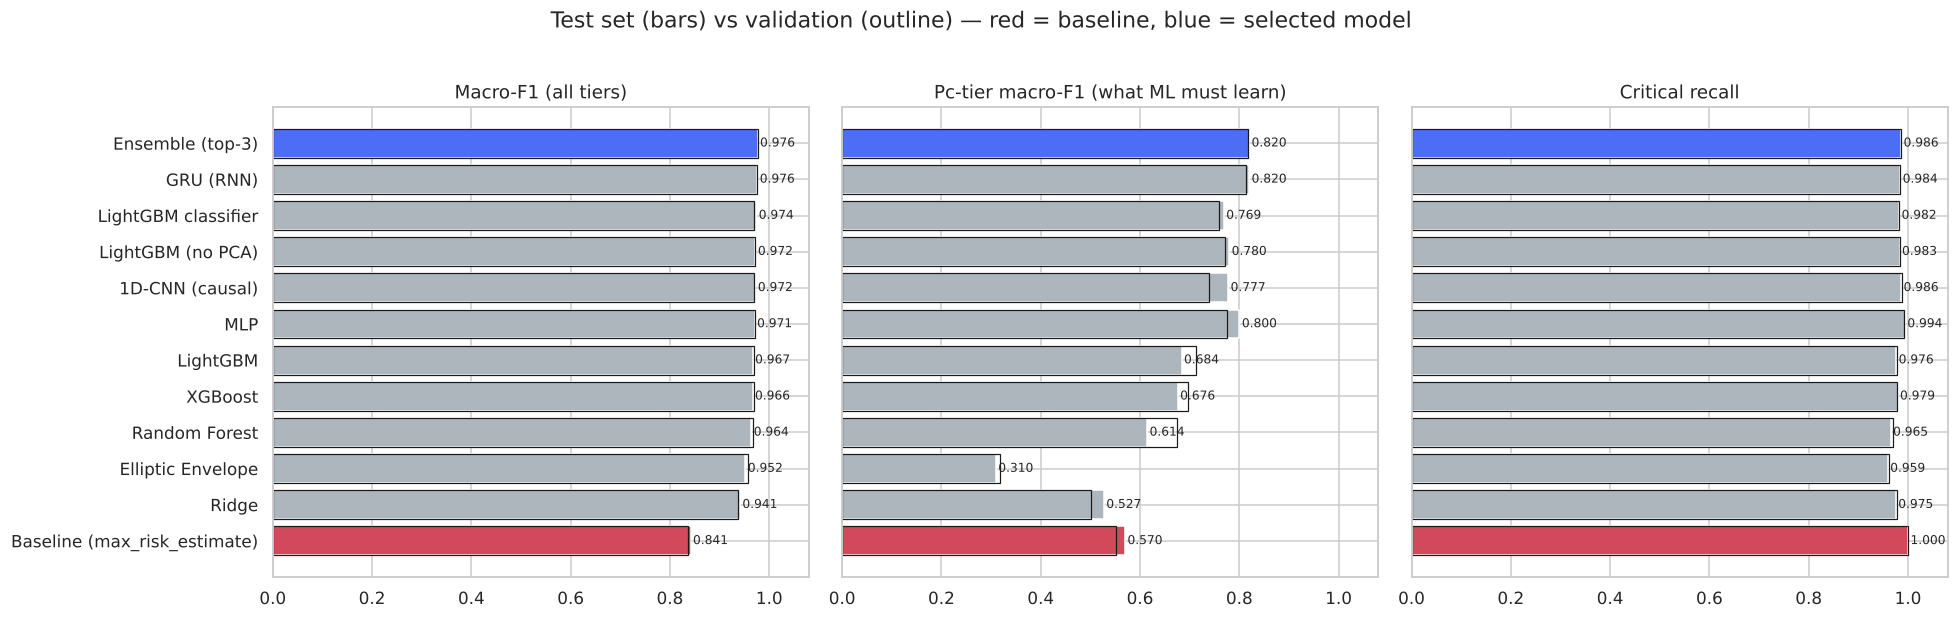

In [22]:
order = test_tbl.sort_values('macro_f1').index
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
for a, met, ttl in zip(ax, ['macro_f1', 'pc_macro_f1', 'critical_recall'], ['Macro-F1 (all tiers)', 'Pc-tier macro-F1 (what ML must learn)', 'Critical recall']):
    c = ['#d1495b' if m == 'Baseline (max_risk_estimate)' else ('#4c6ef5' if m == BEST else '#adb5bd') for m in order]
    a.barh(order, test_tbl.loc[order, met], color=c)
    a.barh(order, val_tbl.loc[order, met], fill=False, edgecolor='k', lw=.8)
    for i, v in enumerate(test_tbl.loc[order, met]): a.text(v + .005, i, f'{v:.3f}', va='center', fontsize=8)
    a.set(title=ttl, xlim=(0, 1.08))
fig.suptitle('Test set (bars) vs validation (outline) — red = baseline, blue = selected model', y=1.02)
plt.tight_layout(); plt.show()

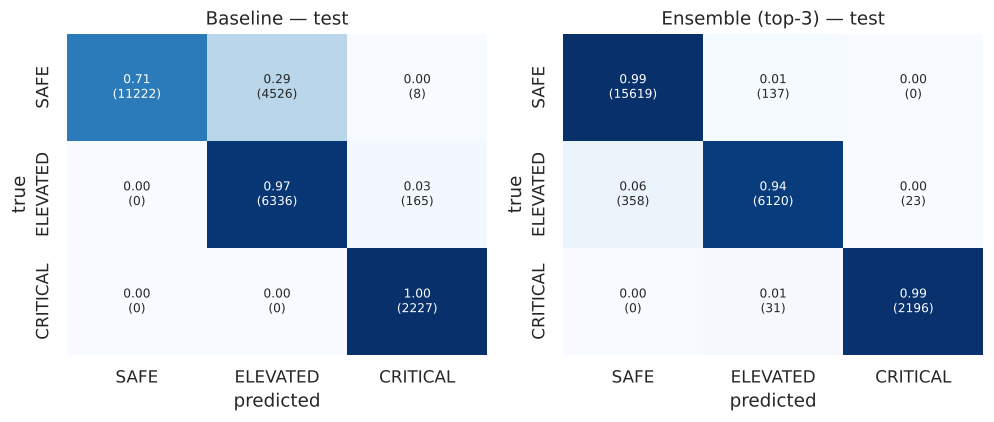

Classification report — Ensemble (top-3) (test)
              precision    recall  f1-score   support

        SAFE      0.978     0.991     0.984     15756
    ELEVATED      0.973     0.941     0.957      6501
    CRITICAL      0.990     0.986     0.988      2227

    accuracy                          0.978     24484
   macro avg      0.980     0.973     0.976     24484
weighted avg      0.978     0.978     0.977     24484



In [23]:
plot_cms({'Baseline': TEST_PRED['Baseline (max_risk_estimate)'], BEST: TEST_PRED[BEST]}, M_test, ' — test')
print(f'Classification report — {BEST} (test)')
print(classification_report(M_test.tier, tier_from(TEST_PRED[BEST], M_test.miss_distance), labels=TIERS, digits=3))

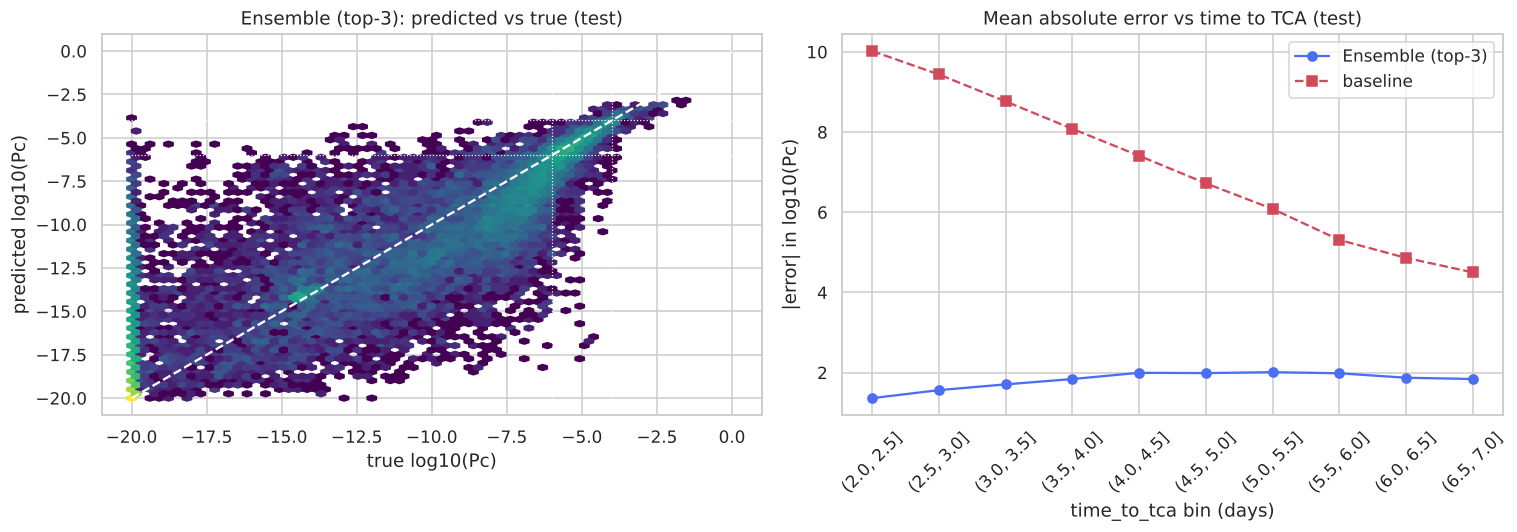

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
yp = np.clip(TEST_PRED[BEST], -20, 0)
ax[0].hexbin(M_test.y, yp, gridsize=60, bins='log', cmap='viridis'); ax[0].plot([-20, 0], [-20, 0], 'w--')
for v in (-6, -4): ax[0].axhline(v, c='w', ls=':', lw=.8); ax[0].axvline(v, c='w', ls=':', lw=.8)
ax[0].set(xlabel='true log10(Pc)', ylabel='predicted log10(Pc)', title=f'{BEST}: predicted vs true (test)')
# error vs time to TCA
err = pd.DataFrame({'tca': M_test.time_to_tca, 'err': np.abs(yp - M_test.y), 'base': np.abs(np.clip(M_test.max_risk_estimate, -20, 0) - M_test.y)})
err['bin'] = pd.cut(err.tca, np.arange(2, 7.5, .5))
e = err.groupby('bin', observed=True)[['err', 'base']].mean()
ax[1].plot(e.index.astype(str), e.err, 'o-', label=BEST, c='#4c6ef5'); ax[1].plot(e.index.astype(str), e.base, 's--', label='baseline', c='#d1495b')
ax[1].set(title='Mean absolute error vs time to TCA (test)', xlabel='time_to_tca bin (days)', ylabel='|error| in log10(Pc)'); ax[1].tick_params(axis='x', rotation=45); ax[1].legend()
plt.tight_layout(); plt.show()

### 9.1b Confusion matrix for every model (test)
Rows = true tier, columns = predicted tier. Each cell shows the row-normalised rate and the raw count.

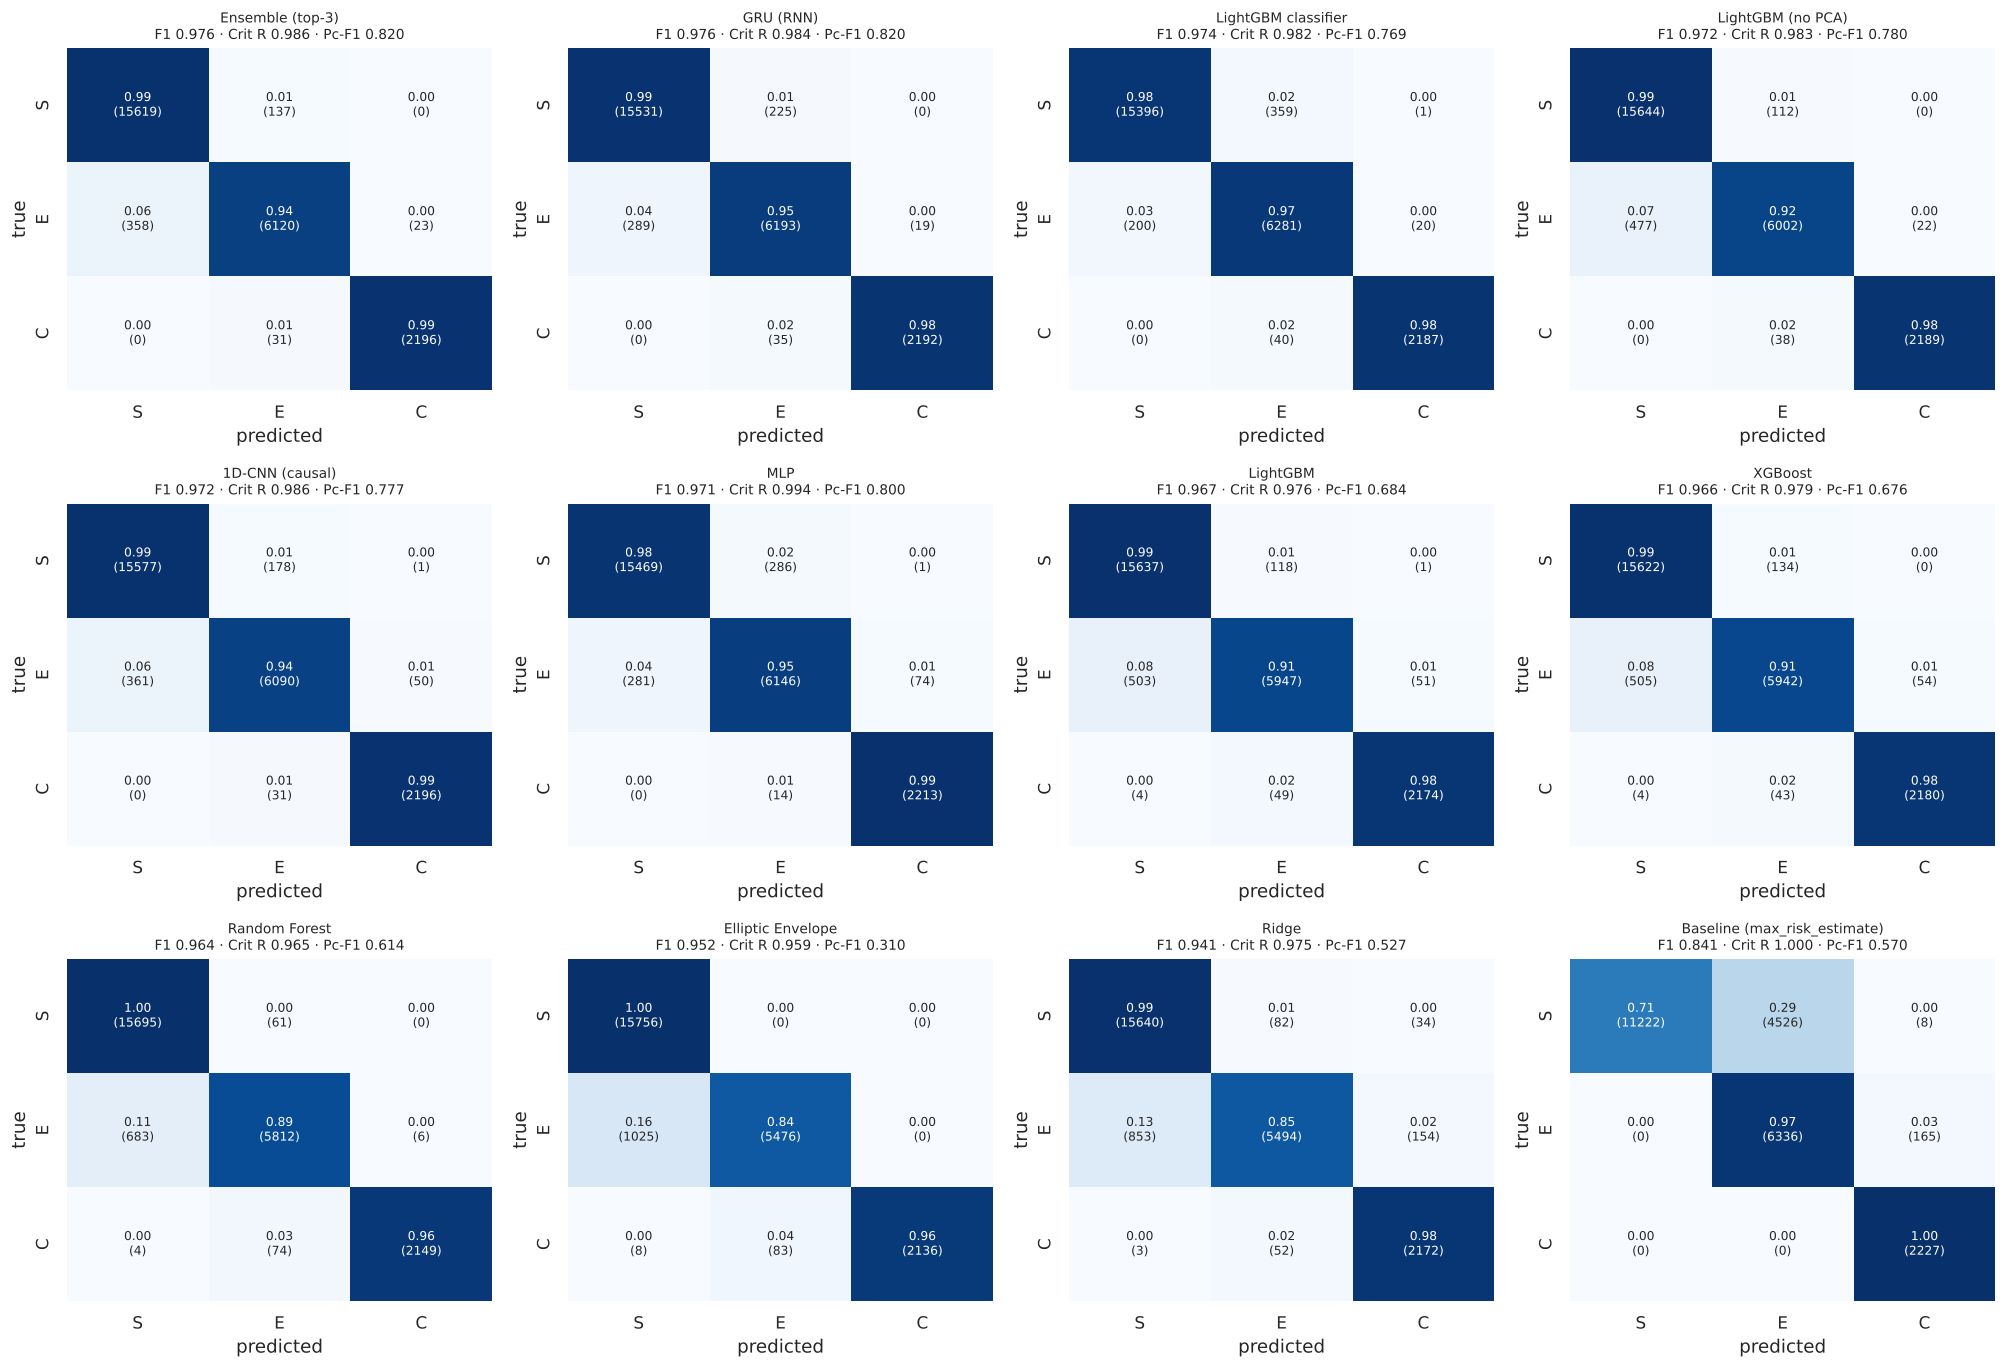

In [25]:
names = list(test_tbl.sort_values('macro_f1', ascending=False).index)
ncol = 4; nrow = int(np.ceil(len(names) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.6 * ncol, 4.2 * nrow))
for a, nm in zip(axes.flat, names):
    cm = confusion_matrix(M_test.tier, tier_from(TEST_PRED[nm], M_test.miss_distance), labels=TIERS)
    cmn = cm / cm.sum(1, keepdims=True)
    sns.heatmap(cmn, annot=np.array([[f'{cmn[i,j]:.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]), fmt='',
                cmap='Blues', vmin=0, vmax=1, xticklabels=['S', 'E', 'C'], yticklabels=['S', 'E', 'C'], cbar=False, ax=a, annot_kws={'size': 8})
    r = test_tbl.loc[nm]
    a.set_title(f'{nm}\nF1 {r.macro_f1:.3f} · Crit R {r.critical_recall:.3f} · Pc-F1 {r.pc_macro_f1:.3f}', fontsize=9)
    a.set_xlabel('predicted'); a.set_ylabel('true')
for a in list(axes.flat)[len(names):]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrices_test.png', dpi=130, bbox_inches='tight'); plt.show()
np.savez(f'{OUT_DIR}/test_predictions_all_models.npz', **{k: v for k, v in TEST_PRED.items()})

### 9.2 What drives the prediction? (PCA-space importance mapped back to features)

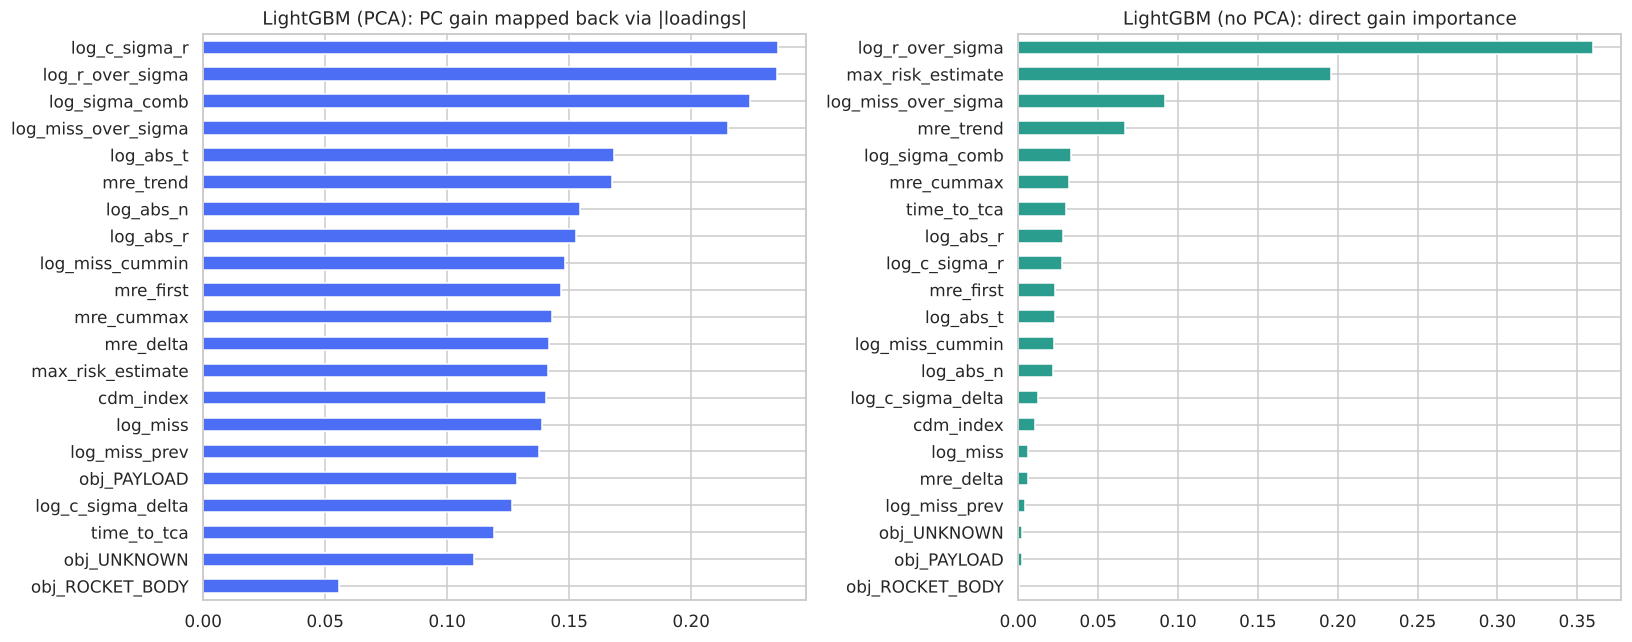

In [26]:
if BEST in classical or BEST.startswith('LightGBM') or BEST.startswith('Ensemble'):
    ref = classical['LightGBM']
    pc_imp = ref.booster_.feature_importance('gain'); pc_imp = pc_imp / pc_imp.sum()
    feat_imp = pd.Series(np.abs(pca.components_).T @ pc_imp, index=SELECTED).sort_values()
    raw_imp = pd.Series(lgb_raw.booster_.feature_importance('gain'), index=SELECTED); raw_imp = (raw_imp / raw_imp.sum()).sort_values()
    fig, ax = plt.subplots(1, 2, figsize=(15, 6))
    feat_imp.plot.barh(ax=ax[0], color='#4c6ef5'); ax[0].set_title('LightGBM (PCA): PC gain mapped back via |loadings|')
    raw_imp.plot.barh(ax=ax[1], color='#2a9d8f'); ax[1].set_title('LightGBM (no PCA): direct gain importance')
    plt.tight_layout(); plt.show()

### 9.3 Recommended operating mode: ML + upper-bound safety net
The baseline never misses a Pc-critical CDM (it uses the conservative upper bound), but it over-flags heavily. The ML model is far more precise but misses some Pc-critical CDMs.
**Hybrid:** use the ML tier, and escalate to Critical whenever the CDM's own `max_risk_estimate ≥ −4`. The −4 threshold comes from the brief, so nothing is tuned on test.

,macro_f1,critical_recall,critical_precision,pc_critical_caught,critical_alerts
Baseline (max_risk_estimate),0.841,1.000,0.928,1.000,2400.000000
Ensemble (top-3),0.976,0.986,0.990,0.867,2219.000000
Hybrid: Ensemble (top-3) + safety net,0.965,1.000,0.927,1.000,2402.000000


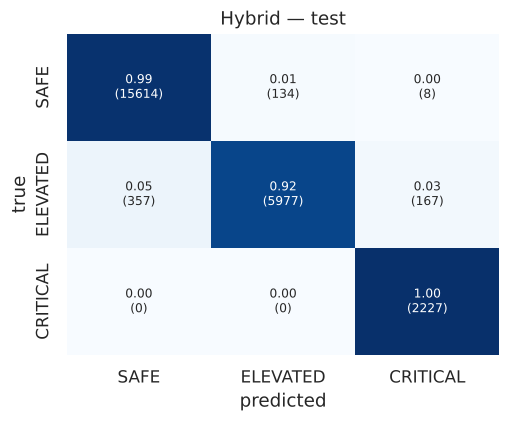

In [27]:
def hybrid_tier(pred_risk, meta):
    t = tier_from(pred_risk, meta.miss_distance.values).astype(object)
    t[meta.max_risk_estimate.values >= -4] = 'CRITICAL'
    return t.astype(str)

def tier_metrics(true_t, pred_t, pc_true):
    return {'macro_f1': f1_score(true_t, pred_t, labels=TIERS, average='macro'),
            'critical_recall': recall_score(true_t, pred_t, labels=['CRITICAL'], average='macro'),
            'critical_precision': precision_score(true_t, pred_t, labels=['CRITICAL'], average='macro'),
            'pc_critical_caught': ((pred_t == 'CRITICAL') & (pc_true == 'CRITICAL')).sum() / (pc_true == 'CRITICAL').sum(),
            'critical_alerts': int((pred_t == 'CRITICAL').sum())}

HYB_TEST = hybrid_tier(TEST_PRED[BEST], M_test)
pc_true_te = pc_tier(M_test.y.values)
hyb = pd.DataFrame({
    'Baseline (max_risk_estimate)': tier_metrics(M_test.tier.values, tier_from(M_test.max_risk_estimate, M_test.miss_distance), pc_true_te),
    f'{BEST}': tier_metrics(M_test.tier.values, tier_from(TEST_PRED[BEST], M_test.miss_distance), pc_true_te),
    f'Hybrid: {BEST} + safety net': tier_metrics(M_test.tier.values, HYB_TEST, pc_true_te)}).T
display(hyb.style.format({c: '{:.3f}' for c in hyb.columns if c != 'critical_alerts'}))
cm = confusion_matrix(M_test.tier, HYB_TEST, labels=TIERS)
fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=np.array([[f'{cm[i,j]/cm[i].sum():.2f}\n({cm[i,j]})' for j in range(3)] for i in range(3)]),
            fmt='', cmap='Blues', xticklabels=TIERS, yticklabels=TIERS, cbar=False, annot_kws={'size': 8}, ax=ax)
ax.set(title='Hybrid — test', xlabel='predicted', ylabel='true'); plt.tight_layout(); plt.show()

## 10. Warnings & operational insights
### 10.1 24-hour warnings (full training data — the test set has no CDMs inside 2 days)
For every event, take the CDMs received within 24 h of TCA and count how many breach the dangerous thresholds.

Events with a CDM inside 24 h of TCA: 9,463 of 13,154
  ↳ miss < 1 km (CRITICAL):     621
  ↳ miss ≤ 5 km (ELEVATED+):    2,440
  ↳ Pc ≥ 1e-4 (manoeuvre):      8
  ↳ final tier counts: {'SAFE': 6999, 'ELEVATED': 1841, 'CRITICAL': 623}


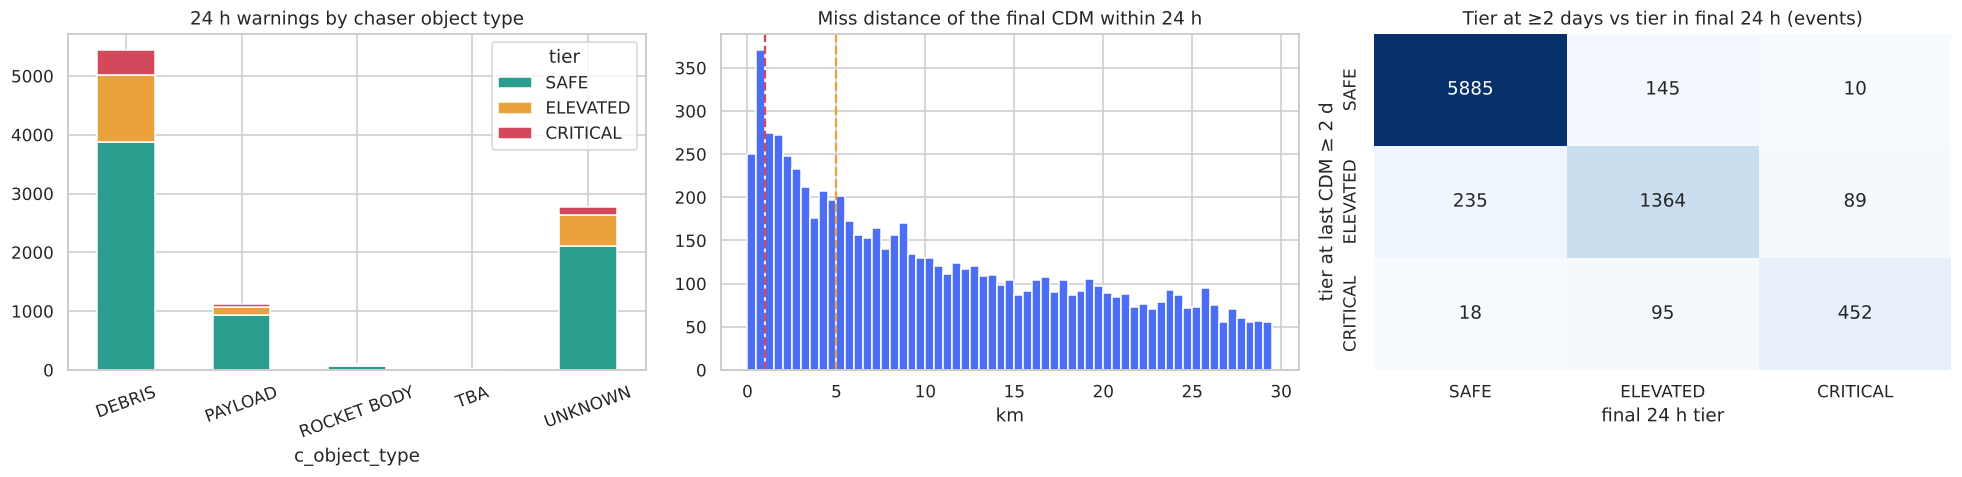

In [28]:
w24 = train_full[train_full.time_to_tca <= 1].sort_values('time_to_tca').groupby('event_id').head(1)   # latest CDM within 24 h
w24 = w24.assign(within_1km=w24.miss_distance < 1000, within_5km=w24.miss_distance <= 5000, pc_crit=w24[LABEL] >= -4)
n_ev = train_full.event_id.nunique()
print(f'Events with a CDM inside 24 h of TCA: {len(w24):,} of {n_ev:,}')
print(f'  ↳ miss < 1 km (CRITICAL):     {w24.within_1km.sum():,}')
print(f'  ↳ miss ≤ 5 km (ELEVATED+):    {w24.within_5km.sum():,}')
print(f'  ↳ Pc ≥ 1e-4 (manoeuvre):      {w24.pc_crit.sum():,}')
print(f'  ↳ final tier counts:', w24.tier.value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
pd.crosstab(w24.c_object_type, w24.tier)[TIERS].plot.bar(stacked=True, ax=ax[0], color=[TIER_COLORS[t] for t in TIERS], rot=20)
ax[0].set_title('24 h warnings by chaser object type')
ax[1].hist(w24.miss_distance / 1e3, bins=np.arange(0, 30, .5), color='#4c6ef5'); ax[1].axvline(1, c=TIER_COLORS['CRITICAL'], ls='--'); ax[1].axvline(5, c=TIER_COLORS['ELEVATED'], ls='--')
ax[1].set(title='Miss distance of the final CDM within 24 h', xlabel='km')
# how often does the tier change between the ≥2-day view and the final view?
early = train_full[train_full.time_to_tca >= 2].sort_values('time_to_tca').groupby('event_id').head(1)[['event_id', 'tier']]
trans = early.merge(w24[['event_id', 'tier']], on='event_id', suffixes=('_2d', '_final'))
sns.heatmap(pd.crosstab(trans.tier_2d, trans.tier_final).reindex(index=TIERS, columns=TIERS), annot=True, fmt='d', cmap='Blues', ax=ax[2], cbar=False)
ax[2].set(title='Tier at ≥2 days vs tier in final 24 h (events)', xlabel='final 24 h tier', ylabel='tier at last CDM ≥ 2 d')
plt.tight_layout(); plt.show()

### 10.2 Early-warning view on the test set (per event)
For each test event: the latest CDM's predicted tier, and the **lead time** — how many days before TCA the model first flagged it Critical.

Event-level tier (latest CDM) — test
              precision    recall  f1-score   support

        SAFE      0.985     0.997     0.991      1481
    ELEVATED      0.984     0.954     0.969       500
    CRITICAL      1.000     0.984     0.992       186

    accuracy                          0.986      2167
   macro avg      0.989     0.978     0.984      2167
weighted avg      0.986     0.986     0.986      2167

Events flagged Critical at some point: 373 / 2167; median lead time 6.03 days before TCA


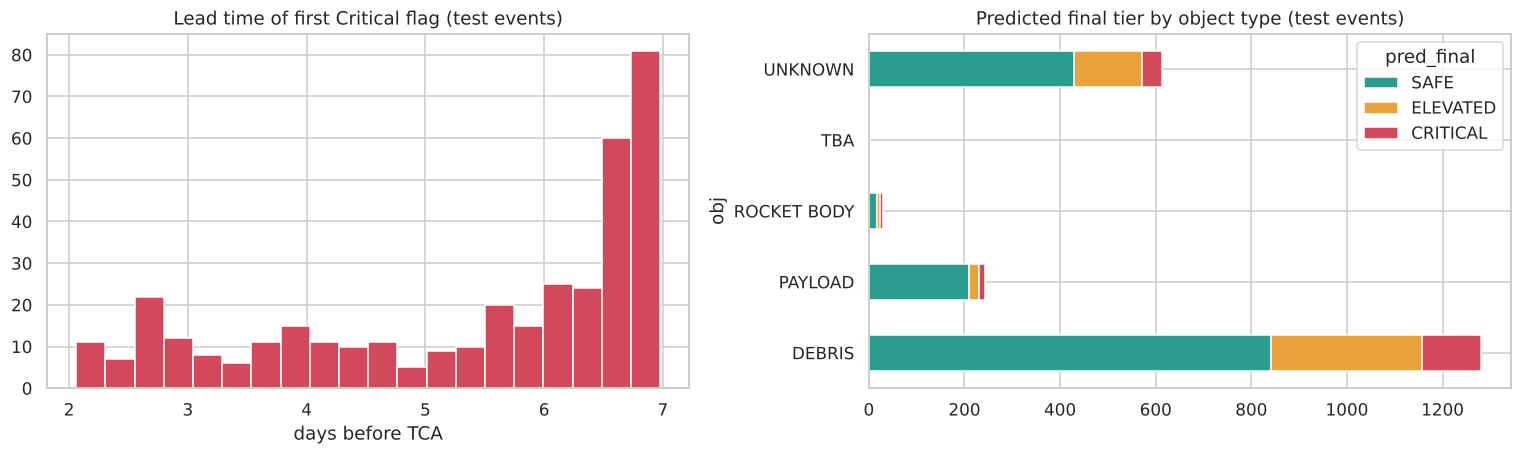

In [29]:
tp = M_test.assign(pred_risk=TEST_PRED[BEST], pred_tier=tier_from(TEST_PRED[BEST], M_test.miss_distance),
                   base_tier=tier_from(M_test.max_risk_estimate, M_test.miss_distance))
ev = tp.groupby('event_id').agg(true_final=('tier', 'last'), pred_final=('pred_tier', 'last'), obj=('c_object_type', 'first'),
                                 last_tca=('time_to_tca', 'last'), min_miss_km=('miss_distance', lambda s: s.min() / 1e3))
first_flag = tp[tp.pred_tier == 'CRITICAL'].groupby('event_id').time_to_tca.max().rename('first_critical_flag_days')
ev = ev.join(first_flag)
print('Event-level tier (latest CDM) — test')
print(classification_report(ev.true_final, ev.pred_final, labels=TIERS, digits=3))
print(f'Events flagged Critical at some point: {ev.first_critical_flag_days.notna().sum()} / {len(ev)}; '
      f'median lead time {ev.first_critical_flag_days.median():.2f} days before TCA')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].hist(ev.first_critical_flag_days.dropna(), bins=20, color=TIER_COLORS['CRITICAL']); ax[0].set(title='Lead time of first Critical flag (test events)', xlabel='days before TCA')
pd.crosstab(ev.obj, ev.pred_final)[TIERS].plot.barh(stacked=True, ax=ax[1], color=[TIER_COLORS[t] for t in TIERS]); ax[1].set_title('Predicted final tier by object type (test events)')
plt.tight_layout(); plt.show()

### 10.3 Human-review flag
CDMs whose predicted log10(Pc) sits within ±0.5 of a decision threshold (−6 or −4) are flagged for an analyst. This is where the model is least certain, and where most errors concentrate.

In [30]:
tp['review_flag'] = (np.abs(tp.pred_risk + 6) < .5) | (np.abs(tp.pred_risk + 4) < .5)
tp['pc_error'] = pc_tier(tp.pred_risk) != tp.pc_tier
print(f'Review-flagged CDMs: {tp.review_flag.mean():.1%} of test rows')
print(f'Pc-tier error rate — flagged: {tp[tp.review_flag].pc_error.mean():.1%} · not flagged: {tp[~tp.review_flag].pc_error.mean():.1%}')
print(f'Share of all Pc-tier errors caught by the flag: {tp[tp.pc_error].review_flag.mean():.1%}')

Review-flagged CDMs: 8.7% of test rows
Pc-tier error rate — flagged: 33.2% · not flagged: 2.8%
Share of all Pc-tier errors caught by the flag: 52.8%


## 11. Failure cases (honest evaluation)
The most dangerous error: the truth is **Critical because of Pc** (miss-distance rule doesn't catch it), but the model says Safe/Elevated.

Pc-critical CDMs in test: 233 · missed by Ensemble (top-3): 31 (baseline missed 0)


,event_id,time_to_tca,miss_distance,c_object_type,max_risk_estimate,risk,pred_risk,pred_tier
4983,441,2.919,1366.0,DEBRIS,-3.666,-3.691,-4.053,ELEVATED
6297,560,2.256,3858.0,DEBRIS,-3.730,-3.728,-4.104,ELEVATED
5009,443,4.420,1299.0,DEBRIS,-3.596,-3.745,-4.049,ELEVATED
6296,560,2.555,3948.0,DEBRIS,-3.753,-3.753,-4.013,ELEVATED
8967,802,3.254,1687.0,UNKNOWN,-3.817,-3.821,-4.162,ELEVATED
3359,294,6.896,1610.0,DEBRIS,-3.579,-3.833,-4.181,ELEVATED
18345,1624,5.616,3931.0,DEBRIS,-3.833,-3.841,-4.058,ELEVATED
8969,802,2.516,1645.0,UNKNOWN,-3.809,-3.848,-4.222,ELEVATED
8965,802,3.938,1803.0,UNKNOWN,-3.875,-3.876,-4.377,ELEVATED
20331,1792,2.933,1966.0,DEBRIS,-3.880,-3.890,-4.163,ELEVATED


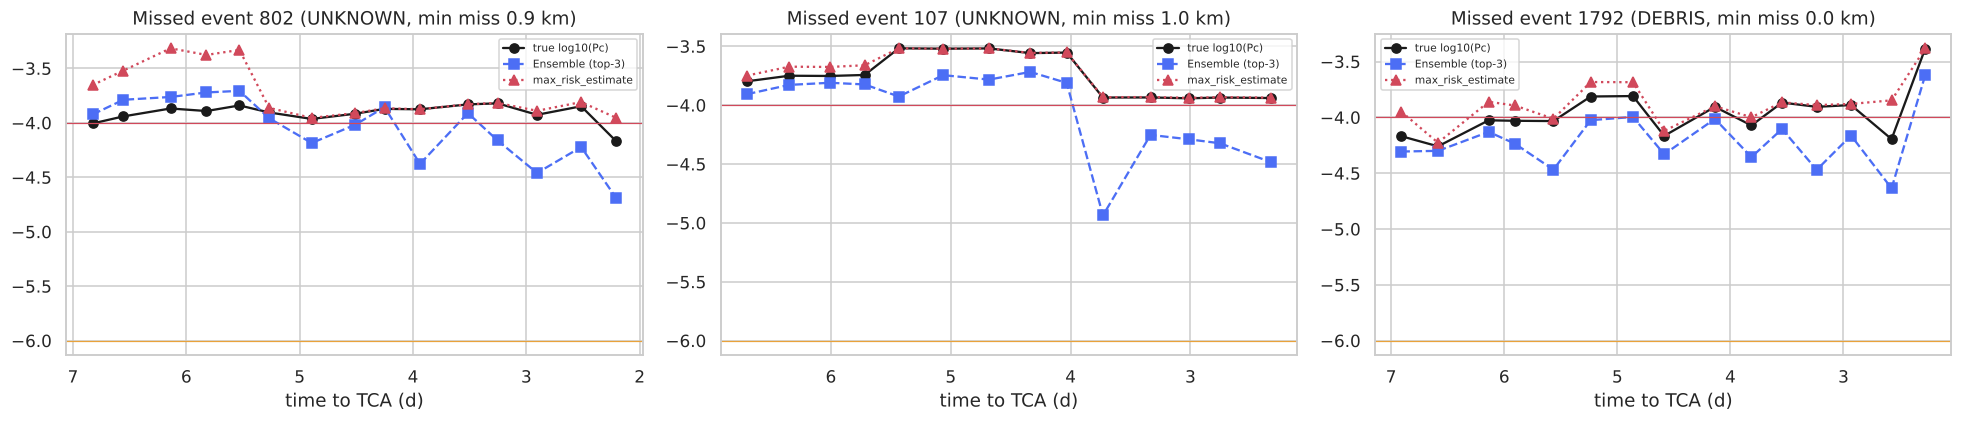

In [31]:
fn = tp[(tp.pc_tier == 'CRITICAL') & (tp.pred_tier != 'CRITICAL')]
print(f'Pc-critical CDMs in test: {(tp.pc_tier == "CRITICAL").sum()} · missed by {BEST}: {len(fn)} '
      f'(baseline missed {((tp.pc_tier == "CRITICAL") & (tp.base_tier != "CRITICAL")).sum()})')
display(fn[['event_id', 'time_to_tca', 'miss_distance', 'c_object_type', 'max_risk_estimate', LABEL, 'pred_risk', 'pred_tier']]
        .sort_values(LABEL, ascending=False).head(10).round(3))
worst_events = fn.groupby('event_id').size().sort_values(ascending=False).index[:3]
if len(worst_events):
    fig, ax = plt.subplots(1, len(worst_events), figsize=(6 * len(worst_events), 4), squeeze=False)
    for a, e in zip(ax[0], worst_events):
        g = tp[tp.event_id == e]
        a.plot(g.time_to_tca, g.y, 'o-', c='k', label='true log10(Pc)')
        a.plot(g.time_to_tca, g.pred_risk, 's--', c='#4c6ef5', label=f'{BEST}')
        a.plot(g.time_to_tca, g.max_risk_estimate, '^:', c='#d1495b', label='max_risk_estimate')
        a.axhline(-4, c=TIER_COLORS['CRITICAL'], lw=.8); a.axhline(-6, c=TIER_COLORS['ELEVATED'], lw=.8)
        a.invert_xaxis(); a.set(title=f'Missed event {e} ({g.c_object_type.iloc[0]}, min miss {g.miss_distance.min()/1e3:.1f} km)', xlabel='time to TCA (d)')
        a.legend(fontsize=7)
    plt.tight_layout(); plt.show()

## 12. Export predictions (for the dashboard)

In [32]:
export = tp[['event_id', 'time_to_tca', 'c_object_type', 'miss_distance', 'relative_position_r', 'relative_position_t', 'relative_position_n',
             'max_risk_estimate', 'pred_risk', 'pred_tier', 'base_tier', 'review_flag', LABEL, 'tier']].rename(
    columns={'pred_risk': 'pred_log10_pc', LABEL: 'true_log10_pc', 'tier': 'true_tier', 'base_tier': 'baseline_tier'})
export['pred_pc'] = 10 ** export.pred_log10_pc.clip(upper=0)
export['hybrid_tier'] = HYB_TEST
export.to_csv(f'{OUT_DIR}/predictions_test.csv', index=False)
ev.to_csv(f'{OUT_DIR}/event_summary_test.csv')
print(f'Saved {OUT_DIR}/predictions_test.csv ({len(export):,} rows), {OUT_DIR}/event_summary_test.csv, {OUT_DIR}/test_metrics.csv')
export.head()

Saved outputs/predictions_test.csv (24,484 rows), outputs/event_summary_test.csv, outputs/test_metrics.csv


,event_id,time_to_tca,c_object_type,miss_distance,relative_position_r,relative_position_t,relative_position_n,max_risk_estimate,pred_log10_pc,pred_tier,baseline_tier,review_flag,true_log10_pc,true_tier,pred_pc,hybrid_tier
0,0,6.842095,UNKNOWN,31816.0,-365.5,26967.0,16880.6,-7.208941,-8.637334,SAFE,SAFE,False,-7.296967,SAFE,2.304976e-09,SAFE
1,0,6.571818,UNKNOWN,31095.0,-361.8,26356.6,16497.2,-7.199833,-8.550358,SAFE,SAFE,False,-7.282496,SAFE,2.816062e-09,SAFE
2,0,6.112986,UNKNOWN,32202.0,-370.7,27294.4,17085.1,-7.217886,-8.681837,SAFE,SAFE,False,-7.316053,SAFE,2.080479e-09,SAFE
3,0,5.921955,UNKNOWN,32878.0,-376.3,27867.5,17443.8,-7.228707,-8.849682,SAFE,SAFE,False,-7.334138,SAFE,1.413571e-09,SAFE
4,0,2.228761,UNKNOWN,32792.0,-375.6,27793.8,17399.4,-7.227312,-10.675511,SAFE,SAFE,False,-7.332267,SAFE,2.111006e-11,SAFE


## 13. Summary
Printed from the run above so the numbers stay in sync with the code.

In [33]:
b, m = test_tbl.loc['Baseline (max_risk_estimate)'], test_tbl.loc[BEST]
print(f"""Selected model (by validation macro-F1): {BEST}
Test, CDM level                 baseline   model
  macro-F1 (3 tiers)            {b.macro_f1:7.3f}  {m.macro_f1:7.3f}
  Critical recall               {b.critical_recall:7.3f}  {m.critical_recall:7.3f}
  Critical precision            {b.critical_precision:7.3f}  {m.critical_precision:7.3f}
  Pc-tier macro-F1              {b.pc_macro_f1:7.3f}  {m.pc_macro_f1:7.3f}
  Pc-critical recall            {b.pc_critical_recall:7.3f}  {m.pc_critical_recall:7.3f}
  RMSE log10(Pc), high-risk     {b.rmse_highrisk:7.3f}  {m.rmse_highrisk:7.3f}

Recommended hybrid (ML tier + escalate when max_risk_estimate ≥ −4), test:
  macro-F1 {hyb.iloc[2].macro_f1:.3f} · Critical recall {hyb.iloc[2].critical_recall:.3f} · Critical precision {hyb.iloc[2].critical_precision:.3f} · Pc-critical caught {hyb.iloc[2].pc_critical_caught:.3f}

Caveats
 - Pc is *predicted* from allowed columns, not computed: full covariances and hard-body radius are not in the allowed set.
 - ~95% of Critical rows are Critical because miss distance < 1 km, which the rule handles exactly; Pc-tier metrics show the ML's real contribution.
 - Test CDMs are all ≥ 2 days before TCA, so train was filtered to match; performance closer to TCA is not measured here.
 - The analyst keeps the final decision; review-flagged CDMs are routed to them.""")

Selected model (by validation macro-F1): Ensemble (top-3)
Test, CDM level                 baseline   model
  macro-F1 (3 tiers)              0.841    0.976
  Critical recall                 1.000    0.986
  Critical precision              0.928    0.990
  Pc-tier macro-F1                0.570    0.820
  Pc-critical recall              1.000    0.717
  RMSE log10(Pc), high-risk       0.483    1.216

Recommended hybrid (ML tier + escalate when max_risk_estimate ≥ −4), test:
  macro-F1 0.965 · Critical recall 1.000 · Critical precision 0.927 · Pc-critical caught 1.000

Caveats
 - Pc is *predicted* from allowed columns, not computed: full covariances and hard-body radius are not in the allowed set.
 - ~95% of Critical rows are Critical because miss distance < 1 km, which the rule handles exactly; Pc-tier metrics show the ML's real contribution.
 - Test CDMs are all ≥ 2 days before TCA, so train was filtered to match; performance closer to TCA is not measured here.
 - The analyst keeps the 